# 🚆 Train Schedule Analysis and Interactive Route Enquiry System Using Python
**Sysslan IT Solutions – Data Analysis Internship Project**

This notebook analyses a static railway timetable dataset (`Dataset1.csv`) and ends with an interactive, dataset-based route enquiry tool. It covers all six levels of the project task list, one level after another.

### ▶ How to run
1. Open this notebook in **Google Colab** and choose **Runtime → Run all**.
2. When **Cell 3** appears, click **Choose Files** and select **`Dataset1.csv`** from your computer. No Google Drive mounting is needed.
3. Wait for the remaining cells to finish. The enquiry widget appears in **Level 6**; the cleaned CSV download is triggered in **Task 3.4**.

### ℹ Ground rules used throughout
* Every number, table and chart is **computed from the uploaded CSV at run time**. Nothing is hard-coded or simulated.
* Problematic records are **flagged, not silently dropped**. The only rows ever removed are *exact* duplicate rows, and every removal is reported.
* The enquiry system is a **static timetable lookup**. It has no live running status, no delays and no real-time railway API.

## 0. Approach in brief

| Topic | Method used in this notebook |
|---|---|
| **Station order** | Rows are ordered by `SN` within each `Train_No` (ties broken by original file position). The alphabetical order of stations is never used. A `Stop_Pos` column (1…n) is derived from that order. |
| **Stops** | *Total recorded stations* = number of rows of a train. *Intermediate stops* = total − 2 (origin and terminus excluded, never below 0). Repeated visits are counted as separate rows. |
| **Time handling** | `HH:MM:SS` strings are validated and converted to seconds. At the origin the arrival and at the terminus the departure are **placeholders** (`00:00:00`) and are treated as *not applicable*, not as midnight. |
| **Midnight rollover** | Within a train, times are "unrolled" onto a continuous timeline: a large backwards jump (default > 12 h) means a new day started. Small backwards steps are reported as time regressions rather than being turned into 24 h errors. |
| **Journey duration** | Final station arrival − first station departure on the unrolled timeline. If a needed endpoint is missing, invalid or an ambiguous `00:00:00`, the duration is marked *unreliable* with a stated reason. |
| **Route categories** | Short / Medium / Long from the train's total route distance (last − first `Distance`), using configurable quantile thresholds (default: terciles). `Route_Number` is never used. |
| **Enquiry system** | Resolves codes, exact names and partial names, finds every train that visits the source before the destination, and computes duration on the unrolled timeline. Built with `ipywidgets`. |

> **Limitations stated up front.** The columns `1A`, `2A`, `3A`, `SL` are not interpreted (their meaning cannot be verified from the data alone), and the dataset has no train names, running days or fares.

## 1. Setup – libraries, configuration and helpers
**Cell 1** imports the libraries and defines every configurable parameter in one place.

In [1]:
# ============================================================
# CELL 1 – Imports, configuration and helper functions
# ============================================================
import io, os, re, difflib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from IPython.display import display, HTML, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelsize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:                       # also lets the notebook run in plain Jupyter
    colab_files = None
    IN_COLAB = False

# ---------------- Configurable parameters ----------------
SHORT_MEDIUM_QUANTILE = 1 / 3             # Short  = distance <= this quantile of train distances
MEDIUM_LONG_QUANTILE = 2 / 3              # Medium = up to this quantile, Long = above it
MANUAL_DISTANCE_THRESHOLDS = None         # e.g. (500, 1200) in DIST_UNIT overrides the quantiles
ROLLOVER_DROP_HOURS = 12                  # a backwards jump larger than this = midnight crossed
MAX_PLAUSIBLE_JOURNEY_HOURS = 120         # longer computed durations are flagged as unreliable
AMBIGUOUS_ENDPOINT_MIDNIGHT_AS_MISSING = True   # see Task 2.1
MAX_AMBIGUOUS_MATCHES = 10                # enquiry: max stations a partial query may match
DIST_UNIT = "units"                       # NEUTRAL label. The dataset never states a unit; set "km" ONLY if you can confirm it.
RESULTS_PAGE_SIZE = 25                    # enquiry results shown per page (ALL results stay available + exportable)
REGRESSION_TOLERANCE_SEC = 0              # a backwards step bigger than this (after rollover logic) is a regression
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CATEGORY_ORDER = ["Short", "Medium", "Long"]
ALL_CATEGORIES = CATEGORY_ORDER + ["Unclassified"]
CAT_COLORS = {"Short": "#4C72B0", "Medium": "#DD8452", "Long": "#55A868", "Unclassified": "#8C8C8C"}

CHART_DIR = os.path.join(OUTPUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

def finish_fig(name):
    """Tidy the layout, SAVE the chart as a PNG in outputs/charts, then show it."""
    plt.tight_layout()
    path = os.path.join(CHART_DIR, f"{name}.png")
    plt.gcf().savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

def save_csv(frame, name, index=False):
    """Save a DataFrame into the outputs folder and report what was written."""
    path = os.path.join(OUTPUT_DIR, name)
    frame.to_csv(path, index=index)
    print(f"💾 Saved: {path}  ({len(frame):,} rows)")
    return path

def offer_download(path):
    """Trigger a browser download in Colab; elsewhere just print the location."""
    if IN_COLAB:
        colab_files.download(path)
    else:
        print(f"(Not running in Colab – file is available at: {path})")

def fmt_hm(seconds):
    """Seconds -> 'H h MM min' (or 'N/A')."""
    if pd.isna(seconds):
        return "N/A"
    total_min = int(round(float(seconds) / 60))
    h, m = divmod(total_min, 60)
    return f"{h} h {m:02d} min"

def seconds_to_hms(sec):
    """Vectorised seconds-of-day -> 'HH:MM:SS' string (NaN stays NaN)."""
    sec = pd.Series(sec)
    ok = sec.notna()
    v = sec.fillna(0).astype("int64")
    out = ((v // 3600) % 24).astype(str).str.zfill(2) + ":" + \
          ((v % 3600) // 60).astype(str).str.zfill(2) + ":" + \
          (v % 60).astype(str).str.zfill(2)
    return out.where(ok)

print("✅ Libraries loaded. Running in Google Colab:", IN_COLAB)

✅ Libraries loaded. Running in Google Colab: True


## 2. Upload and load `Dataset1.csv`
**Cell 2** opens Colab's file-upload dialog. Click **Choose Files**, select `Dataset1.csv` and wait for the upload to finish.

Text-like columns are read as text on purpose. Train numbers keep any leading zeros, and station codes such as `NA` are not mistaken for "missing". The unmodified table is kept as `raw`, and a fingerprint of it is stored so the notebook can prove at the end that the original data was never changed.

In [2]:
# ============================================================
# CELL 2 – Upload and load the dataset
# ============================================================
LOCAL_FALLBACK = os.environ.get("DATASET_PATH", "Dataset1.csv")   # used only outside Colab
TEXT_COLS = ["Train_No", "Station_Code", "Station_Name", "Arrival_time", "Departure_Time"]
EXPECTED_COLS = ["SN", "Train_No", "Station_Code", "1A", "2A", "3A", "SL", "Station_Name",
                 "Route_Number", "Arrival_time", "Departure_Time", "Distance"]

def load_dataset():
    if IN_COLAB:
        print("📂 Click 'Choose Files' below and select Dataset1.csv ...")
        uploaded = colab_files.upload()
        if not uploaded:
            raise FileNotFoundError("No file was uploaded. Re-run this cell and select Dataset1.csv.")
        name = next((n for n in uploaded if n.lower().endswith(".csv")), next(iter(uploaded)))
        source = io.BytesIO(uploaded[name])
    else:
        name, source = LOCAL_FALLBACK, LOCAL_FALLBACK
    # Everything is read as TEXT and nothing is stripped, so 'raw' is byte-for-byte what was uploaded.
    frame = pd.read_csv(source, dtype=str, keep_default_na=False, na_values=[""])
    frame.columns = frame.columns.str.strip()
    return name, frame

file_name, raw = load_dataset()
missing_cols = [c for c in EXPECTED_COLS if c not in raw.columns]
if missing_cols:
    raise ValueError(f"The uploaded file is missing expected columns: {missing_cols}. "
                     f"Columns found: {list(raw.columns)}")

RAW_FINGERPRINT = int(pd.util.hash_pandas_object(raw, index=True).sum())   # proves 'raw' is never modified
print(f"✅ Loaded '{file_name}': {raw.shape[0]:,} rows × {raw.shape[1]} columns")

📂 Click 'Choose Files' below and select Dataset1.csv ...


Saving Dataset1.csv to Dataset1.csv
✅ Loaded 'Dataset1.csv': 186,074 rows × 12 columns


# LEVEL 1 – BASIC DATA REVIEW

## Task 1.1 – Dataset overview
**Cell 3** reports size, column types, first/last records, unique trains and stations, memory use and statistical summaries. It also profiles `Route_Number` and the `1A / 2A / 3A / SL` columns so that no assumptions are made about them.

In [3]:
# ============================================================
# CELL 3 – Task 1.1: Dataset overview
# ============================================================
print("=" * 78)
print("TASK 1.1 – DATASET OVERVIEW")
print("=" * 78)
print(f"Total records (rows)      : {raw.shape[0]:,}")
print(f"Total attributes (columns): {raw.shape[1]}")
print(f"Unique trains (Train_No)  : {raw['Train_No'].nunique():,}")
print(f"Unique station codes      : {raw['Station_Code'].nunique():,}")
print(f"Unique station names      : {raw['Station_Name'].nunique():,}")

print("\n▶ Column names, data types and completeness")
_num_ok = {c: bool(pd.to_numeric(raw[c].dropna(), errors="coerce").notna().all()) for c in raw.columns}
schema = pd.DataFrame({"stored_as": raw.dtypes.astype(str),
                       "interpreted_as": ["numeric" if _num_ok[c] and c not in ("Train_No", "Station_Code") else "text" for c in raw.columns],
                       "non_null": raw.notna().sum(), "missing": raw.isna().sum(), "unique_values": raw.nunique()})
display(schema)

print("\n▶ First 5 records")
display(raw.head())
print("▶ Last 5 records")
display(raw.tail())

print("\n▶ Memory usage")
mem = raw.memory_usage(deep=True)
display(pd.DataFrame({"memory_KB": mem / 1024}))
print(f"Total memory: {mem.sum() / 1024 ** 2:,.2f} MB")

NUMERIC_COLS = ["SN", "1A", "2A", "3A", "SL", "Route_Number", "Distance"]
raw_num = raw[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce")      # numeric VIEW only; 'raw' stays text
unparseable = (raw_num.isna() & raw[NUMERIC_COLS].notna()).sum()
print("\n▶ Statistical summary – numeric columns")
display(raw_num.describe().T)
print("Values in numeric columns that are present but not numeric:", unparseable.to_dict())
print("▶ Statistical summary – text columns")
display(raw[TEXT_COLS].describe().T)

print("\n▶ Profiling columns whose meaning must not be assumed")
print(f"Route_Number unique values: {sorted(raw['Route_Number'].dropna().unique().tolist())[:10]}")
for c in ["1A", "2A", "3A", "SL"]:
    vc = raw[c].value_counts(dropna=False)
    print(f"{c:>2}: dtype={raw[c].dtype}, unique={raw[c].nunique()}, most common values={vc.head(5).to_dict()}")
print("\nNote: the meaning of 1A/2A/3A/SL cannot be verified from the data itself, so they are only "
      "carried along as descriptive columns and are not used in any calculation.")

TASK 1.1 – DATASET OVERVIEW
Total records (rows)      : 186,074
Total attributes (columns): 12
Unique trains (Train_No)  : 11,113
Unique station codes      : 8,147
Unique station names      : 8,099

▶ Column names, data types and completeness


,stored_as,interpreted_as,non_null,missing,unique_values
SN,object,numeric,186074,0,118
Train_No,object,text,186074,0,11113
Station_Code,object,text,186074,0,8147
1A,object,numeric,186074,0,3097
2A,object,numeric,186074,0,3097
3A,object,numeric,186074,0,3097
SL,object,numeric,186074,0,3100
Station_Name,object,text,186074,0,8099
Route_Number,object,numeric,186074,0,1
Arrival_time,object,text,186074,0,1440



▶ First 5 records


,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
0,1,107,SWV,100,100,100,100,SAWANTWADI R,1,00:00:00,10:25:00,0
1,2,107,THVM,260,228,196,164,THIVIM,1,11:06:00,11:08:00,32
2,3,107,KRMI,345,296,247,198,KARMALI,1,11:28:00,11:30:00,49
3,4,107,MAO,490,412,334,256,MADGOAN JN.,1,12:10:00,00:00:00,78
4,1,108,MAO,100,100,100,100,MADGOAN JN.,1,00:00:00,20:30:00,0


▶ Last 5 records


,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
186069,1,22439,NDLS,100,100,100,100,NEW DELHI,1,00:00:00,06:00:00,0
186070,2,22439,UMB,1095,896,697,1095,AMBALA CANT JN,1,08:08:00,08:10:00,199
186071,3,22439,LDH,1660,1348,1036,1660,LUDHIANA JN,1,09:19:00,09:21:00,312
186072,4,22439,JAT,2985,2408,1831,2985,JAMMU TAWI,1,12:38:00,12:40:00,577
186073,5,22439,SVDK,3375,2720,2065,3375,SHMATA VD KATRA,1,14:00:00,00:00:00,655


... (3 outputs left out)

,count,mean,std,min,25%,50%,75%,max
SN,"186,074.00",13.91,12.78,1.00,5.00,11.00,18.00,118.00
1A,"186,074.00","1,506.77","2,418.72",100.00,215.00,465.00,"1,555.00","21,400.00"
2A,"186,074.00","1,225.42","1,934.98",100.00,192.00,392.00,"1,264.00","17,140.00"
3A,"186,074.00",944.06,"1,451.23",100.00,169.00,319.00,973.00,"12,880.00"
SL,"186,074.00",662.74,967.52,100.00,146.00,246.00,682.00,"8,620.00"
Route_Number,"186,074.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00
Distance,"186,074.00",281.35,483.74,0.00,23.00,73.00,291.00,"4,260.00"


Values in numeric columns that are present but not numeric: {'SN': 0, '1A': 0, '2A': 0, '3A': 0, 'SL': 0, 'Route_Number': 0, 'Distance': 0}
▶ Statistical summary – text columns


,count,unique,top,freq
Train_No,186074,11113,53041,118
Station_Code,186074,8147,CSMT,1027
Station_Name,186074,8099,CST-MUMBAI,1027
Arrival_time,186074,1440,00:00:00,2003
Departure_Time,186074,1440,00:00:00,1970



▶ Profiling columns whose meaning must not be assumed
Route_Number unique values: ['1']
1A: dtype=object, unique=3097, most common values={'100': 11124, '130': 2303, '185': 1960, '125': 1880, '195': 1851}
2A: dtype=object, unique=3097, most common values={'100': 11124, '124': 2303, '168': 1960, '120': 1880, '176': 1851}
3A: dtype=object, unique=3097, most common values={'100': 11124, '118': 2303, '151': 1960, '115': 1880, '157': 1851}
SL: dtype=object, unique=3100, most common values={'100': 11124, '112': 2303, '134': 1960, '110': 1880, '138': 1851}

Note: the meaning of 1A/2A/3A/SL cannot be verified from the data itself, so they are only carried along as descriptive columns and are not used in any calculation.


### Preparing the working table
**Cell 4** creates the working copy `df` (the raw table stays untouched) and does three things:
1. Strips stray whitespace and upper-cases station codes. Text values are otherwise unchanged.
2. Removes **exact** duplicate rows only. They are logged in `removed_exact_duplicates` and explained again in Task 3.2.
3. Orders each train by `SN` (ties keep the original file order) and derives `Stop_Pos` and `N_Stations`.

In [4]:
# ============================================================
# CELL 4 – Working copy, exact-duplicate handling, station ordering
# ============================================================
ORIG_COLS = list(raw.columns)

# STEP 1 – EXACT duplicates are judged on the ORIGINAL uploaded text, BEFORE any normalisation.
raw_exact_mask = raw.duplicated(subset=ORIG_COLS, keep="first")

# STEP 2 – normalisation is applied to a COPY ('raw' is never touched):
#   trim whitespace, upper-case station codes, convert SN / Distance to numbers.
df = raw.copy()
for c in ORIG_COLS:
    df[c] = df[c].str.strip()
df["Station_Code"] = df["Station_Code"].str.upper()
df["SN"] = pd.to_numeric(df["SN"], errors="coerce")
df["Distance"] = pd.to_numeric(df["Distance"], errors="coerce")
df["Row_ID"] = np.arange(len(df))                       # position in the uploaded file
print(f"SN values missing / not numeric      : {int(df['SN'].isna().sum()):,}")
print(f"Distance values missing / not numeric: {int(df['Distance'].isna().sum()):,}")

# STEP 3 – duplicates that only APPEAR after normalisation (different raw text, same cleaned values).
#   They are FLAGGED and KEPT: they are not provably identical records.
norm_dup_mask = df.duplicated(subset=ORIG_COLS, keep="first")
normalized_only_mask = norm_dup_mask & ~raw_exact_mask
normalized_group_mask = df.duplicated(subset=ORIG_COLS, keep=False) & ~raw.duplicated(subset=ORIG_COLS, keep=False)
normalized_duplicate_groups = raw[normalized_group_mask].assign(Row_ID=df.loc[normalized_group_mask, "Row_ID"]) \
                                .sort_values("Row_ID")
df["Normalized_Duplicate"] = normalized_only_mask

# STEP 4 – only the EXACT duplicates are removed, and every removed row is kept in a log.
removed_exact_duplicates = raw[raw_exact_mask].assign(Row_ID=df.loc[raw_exact_mask, "Row_ID"])
df = df[~raw_exact_mask].copy()
print(f"Exact duplicate rows in the raw file (removed, logged): {len(removed_exact_duplicates):,}")
print(f"Duplicates that appear only after normalisation (kept, flagged): {int(normalized_only_mask.sum()):,}")

# Station sequence: order by SN inside each train, original file order breaks ties
df = df.sort_values(["Train_No", "SN", "Row_ID"], kind="mergesort").reset_index(drop=True)
df["Stop_Pos"] = df.groupby("Train_No").cumcount() + 1
df["N_Stations"] = df.groupby("Train_No")["Station_Code"].transform("size")
print(f"Working table: {len(df):,} rows, {df['Train_No'].nunique():,} trains")
display(df[["Train_No", "SN", "Stop_Pos", "N_Stations", "Station_Code", "Station_Name", "Distance"]].head(8))

SN values missing / not numeric      : 0
Distance values missing / not numeric: 0
Exact duplicate rows in the raw file (removed, logged): 0
Duplicates that appear only after normalisation (kept, flagged): 0
Working table: 186,074 rows, 11,113 trains


,Train_No,SN,Stop_Pos,N_Stations,Station_Code,Station_Name,Distance
0,10103,1,1,20,CSMT,CST-MUMBAI,0
1,10103,2,2,20,DR,DADAR,8
2,10103,3,3,20,TNA,THANE,33
3,10103,4,4,20,PNVL,PANVEL,70
4,10103,5,5,20,MNI,MANGAON,177
5,10103,6,6,20,KHED,KHED,245
6,10103,7,7,20,CHI,CHIPLUN,275
7,10103,8,8,20,SGR,SANGMESHWAR,317


## Task 1.2 – Starting and ending station of every train
The first and last rows of each train **in station-sequence order** (`SN`) give the start and end station. The full result is exported to CSV.

In [5]:
# ============================================================
# CELL 5 – Task 1.2: Starting and ending stations
# ============================================================
first_rows = df.loc[df["Stop_Pos"].eq(1), ["Train_No", "Station_Code", "Station_Name"]]\
               .rename(columns={"Station_Code": "Start_Code", "Station_Name": "Start_Station"})
last_rows = df.loc[df["Stop_Pos"].eq(df["N_Stations"]), ["Train_No", "Station_Code", "Station_Name"]]\
              .rename(columns={"Station_Code": "End_Code", "Station_Name": "End_Station"})
counts = df.groupby("Train_No", sort=False).agg(Total_Recorded_Stations=("Station_Code", "size"),
                                                Distinct_Stations=("Station_Code", "nunique")).reset_index()

trains = first_rows.merge(last_rows, on="Train_No").merge(counts, on="Train_No")
trains["Route"] = trains["Start_Station"] + " (" + trains["Start_Code"] + ") → " + \
                  trains["End_Station"] + " (" + trains["End_Code"] + ")"

view_1_2 = trains[["Train_No", "Start_Code", "Start_Station", "End_Code", "End_Station", "Total_Recorded_Stations"]]
print(f"Start/end stations identified for {len(view_1_2):,} trains\n")
display(view_1_2.head(15))
save_csv(view_1_2, "level1_train_start_end.csv")

Start/end stations identified for 11,113 trains



,Train_No,Start_Code,Start_Station,End_Code,End_Station,Total_Recorded_Stations
0,10103,CSMT,CST-MUMBAI,MAO,MADGOAN JN.,20
1,10104,MAO,MADGOAN JN.,CSMT,CST-MUMBAI,20
2,1011,CSMT,CST-MUMBAI,NGP,NAGPUR JN.(C,18
3,10111,CSMT,CST-MUMBAI,MAO,MADGOAN JN.,20
4,10112,MAO,MADGOAN JN.,CSMT,CST-MUMBAI,20
5,10215,MAO,MADGOAN JN.,ERS,ERNAKULAM. J,13
6,10216,ERS,ERNAKULAM. J,MAO,MADGOAN JN.,13
7,1037,LTT,LOKMANYA TIL,SWV,SAWANTWADI R,10
8,1038,SWV,SAWANTWADI R,LTT,LOKMANYA TIL,10
9,1045,LTT,LOKMANYA TIL,KRMI,KARMALI,11


💾 Saved: outputs/level1_train_start_end.csv  (11,113 rows)


'outputs/level1_train_start_end.csv'

## Task 1.3 – Number of stops per train
Two different measures are kept apart:

* **Total recorded stations** – every row of the train, including origin and terminus.
* **Intermediate stops** – rows strictly between origin and terminus, i.e. `total − 2` (minimum 0).

Repeated visits to the same station are **kept** and counted. `Repeated_Station_Records` shows how many rows are repeats.

In [6]:
# ============================================================
# CELL 6 – Task 1.3: Number of stops per train
# ============================================================
trains["Intermediate_Stops"] = (trains["Total_Recorded_Stations"] - 2).clip(lower=0)
trains["Repeated_Station_Records"] = trains["Total_Recorded_Stations"] - trains["Distinct_Stations"]

print(f"Trains with repeated station codes (circular / looping routes kept as-is): "
      f"{(trains['Repeated_Station_Records'] > 0).sum():,}\n")
display(trains[["Train_No", "Total_Recorded_Stations", "Intermediate_Stops", "Distinct_Stations",
                "Repeated_Station_Records"]].head(15))

print("▶ Summary of the two measures")
display(trains[["Total_Recorded_Stations", "Intermediate_Stops"]].describe().T)
save_csv(trains[["Train_No", "Total_Recorded_Stations", "Intermediate_Stops",
                 "Distinct_Stations", "Repeated_Station_Records"]], "level1_stops_per_train.csv")

Trains with repeated station codes (circular / looping routes kept as-is): 20



,Train_No,Total_Recorded_Stations,Intermediate_Stops,Distinct_Stations,Repeated_Station_Records
0,10103,20,18,20,0
1,10104,20,18,20,0
2,1011,18,16,18,0
3,10111,20,18,20,0
4,10112,20,18,20,0
5,10215,13,11,13,0
6,10216,13,11,13,0
7,1037,10,8,10,0
8,1038,10,8,10,0
9,1045,11,9,11,0


▶ Summary of the two measures


,count,mean,std,min,25%,50%,75%,max
Total_Recorded_Stations,"11,113.00",16.74,12.99,2.00,8.00,15.00,22.00,118.00
Intermediate_Stops,"11,113.00",14.74,12.99,0.00,6.00,13.00,20.00,116.00


💾 Saved: outputs/level1_stops_per_train.csv  (11,113 rows)


'outputs/level1_stops_per_train.csv'

## Task 1.4 – Trains with maximum and minimum stops
Ties are handled by selecting **every** train whose value equals the maximum or minimum (not just the first one). The minimum is frequently shared by a very large number of trains, so the screen shows a sample and the full list is exported.

In [7]:
# ============================================================
# CELL 7 – Task 1.4: Maximum and minimum stops (ties included)
# ============================================================
cols_1_4 = ["Train_No", "Route", "Total_Recorded_Stations", "Intermediate_Stops"]
max_stops = trains["Intermediate_Stops"].max()
min_stops = trains["Intermediate_Stops"].min()
max_trains = trains[trains["Intermediate_Stops"] == max_stops][cols_1_4]
min_trains = trains[trains["Intermediate_Stops"] == min_stops][cols_1_4]

print(f"MAXIMUM intermediate stops = {max_stops}  →  {len(max_trains):,} train(s) share this value")
display(max_trains.head(25))
print(f"\nMINIMUM intermediate stops = {min_stops}  →  {len(min_trains):,} train(s) share this value")
display(min_trains.head(25))
if len(min_trains) > 25:
    print(f"(showing 25 of {len(min_trains):,}; the full list is exported)")
save_csv(max_trains, "level1_max_stops_trains.csv")
save_csv(min_trains, "level1_min_stops_trains.csv")

MAXIMUM intermediate stops = 116  →  1 train(s) share this value


,Train_No,Route,Total_Recorded_Stations,Intermediate_Stops
5796,53041,HOWRAH JN. (HWH) → JAYNAGAR (JYG),118,116



MINIMUM intermediate stops = 0  →  1,249 train(s) share this value


,Train_No,Route,Total_Recorded_Stations,Intermediate_Stops
217,12049,AGRA CANTT (AGC) → HAZRAT NIZAM (NZM),2,0
218,12050,HAZRAT NIZAM (NZM) → AGRA CANTT (AGC),2,0
415,12267,MUMBAI CENTR (BCT) → AHMEDABAD (ADI),2,0
416,12268,AHMEDABAD (ADI) → MUMBAI CENTR (BCT),2,0
421,12275,ALLAHABAD JN (ALD) → NEW DELHI (NDLS),2,0
422,12276,NEW DELHI (NDLS) → ALLAHABAD JN (ALD),2,0
1125,13109,KOLKATA (KOAA) → GEDE (GEDE),2,0
1126,13110,GEDE (GEDE) → KOLKATA (KOAA),2,0
1135,13129,KOLKATA (KOAA) → PETRAPOLE (PTPL),2,0
1136,13130,PETRAPOLE (PTPL) → KOLKATA (KOAA),2,0


(showing 25 of 1,249; the full list is exported)
💾 Saved: outputs/level1_max_stops_trains.csv  (1 rows)
💾 Saved: outputs/level1_min_stops_trains.csv  (1,249 rows)


'outputs/level1_min_stops_trains.csv'

# LEVEL 2 – SIMPLE DATA PROCESSING

## Task 2.1 – Standardise schedule fields
`Arrival_time` and `Departure_Time` are validated against `HH:MM:SS` (hours 0-23, minutes and seconds 0-59). Each value is classed as **ok**, **missing** or **invalid**. The original columns are never modified. New columns are added:

| New column | Meaning |
|---|---|
| `Arrival_Std`, `Departure_Std` | Standardised `HH:MM:SS` text of every valid value (endpoints unchanged) |
| `Arrival_Clean`, `Departure_Clean` | Same, but endpoint **placeholders** (and ambiguous endpoint midnights) are blank |

**Endpoint rule.** A train has no arrival at its origin and no departure at its terminus, so a `00:00:00` there is a placeholder and not a real midnight. If the *meaningful* endpoint value (origin departure, terminus arrival) is also `00:00:00`, it cannot be told apart from a genuine midnight. Such values are called **ambiguous** and treated as unknown (switch `AMBIGUOUS_ENDPOINT_MIDNIGHT_AS_MISSING` in Cell 1 to change this). `00:00:00` at intermediate stations is kept as a real midnight time.

In [8]:
# ============================================================
# CELL 8 – Task 2.1: Standardise and validate time fields
# ============================================================
def parse_time_series(s):
    """Return (seconds_since_midnight, status) with status in {'ok','missing','invalid'}."""
    s = s.astype("object")
    missing = s.isna() | s.astype(str).str.strip().eq("")
    ext = s.where(~missing).astype("object").str.extract(r"^\s*(\d{1,2}):(\d{2})(?::(\d{2}))?\s*$")
    h = pd.to_numeric(ext[0]); m = pd.to_numeric(ext[1]); sec = pd.to_numeric(ext[2]).fillna(0)
    valid = h.notna() & (h < 24) & (m < 60) & (sec < 60)
    seconds = (h * 3600 + m * 60 + sec).where(valid)
    status = pd.Series(np.where(missing, "missing", np.where(valid, "ok", "invalid")), index=s.index)
    return seconds, status

df["Arr_sec_raw"], df["Arr_status"] = parse_time_series(df["Arrival_time"])
df["Dep_sec_raw"], df["Dep_status"] = parse_time_series(df["Departure_Time"])
df["Arrival_Std"] = seconds_to_hms(df["Arr_sec_raw"])
df["Departure_Std"] = seconds_to_hms(df["Dep_sec_raw"])

is_first = df["Stop_Pos"].eq(1)
is_last = df["Stop_Pos"].eq(df["N_Stations"])
arr_zero = df["Arr_sec_raw"].eq(0)
dep_zero = df["Dep_sec_raw"].eq(0)

df["Arr_Placeholder"] = is_first & arr_zero                       # origin: no arrival
df["Dep_Placeholder"] = is_last & dep_zero                        # terminus: no departure
df["Dep_Ambiguous"] = is_first & ~is_last & arr_zero & dep_zero   # origin departure also 00:00:00
df["Arr_Ambiguous"] = is_last & ~is_first & arr_zero & dep_zero   # terminus arrival also 00:00:00

df["Arr_sec"] = df["Arr_sec_raw"].mask(df["Arr_Placeholder"] | (df["Arr_Ambiguous"] & AMBIGUOUS_ENDPOINT_MIDNIGHT_AS_MISSING))
df["Dep_sec"] = df["Dep_sec_raw"].mask(df["Dep_Placeholder"] | (df["Dep_Ambiguous"] & AMBIGUOUS_ENDPOINT_MIDNIGHT_AS_MISSING))
df["Arrival_Clean"] = seconds_to_hms(df["Arr_sec"])
df["Departure_Clean"] = seconds_to_hms(df["Dep_sec"])

summary_2_1 = pd.DataFrame({
    "Arrival_time": df["Arr_status"].value_counts(),
    "Departure_Time": df["Dep_status"].value_counts()}).reindex(["ok", "missing", "invalid"]).fillna(0).astype(int)
print("▶ Validation result for every time value")
display(summary_2_1)
print(f"Origin arrival placeholders (00:00:00)       : {int(df['Arr_Placeholder'].sum()):,}")
print(f"Terminus departure placeholders (00:00:00)   : {int(df['Dep_Placeholder'].sum()):,}")
print(f"Ambiguous origin departures (00:00:00)       : {int(df['Dep_Ambiguous'].sum()):,}")
print(f"Ambiguous terminus arrivals (00:00:00)       : {int(df['Arr_Ambiguous'].sum()):,}")

print("\n▶ Before / after standardisation (original columns preserved)")
display(df[["Train_No", "Stop_Pos", "Station_Code", "Arrival_time", "Arrival_Std", "Arrival_Clean",
            "Departure_Time", "Departure_Std", "Departure_Clean"]].head(10))
bad = df[(df["Arr_status"] == "invalid") | (df["Dep_status"] == "invalid")]
if len(bad):
    print(f"\n⚠ Rows with invalid time text ({len(bad):,}) – kept and flagged, never replaced by zero:")
    display(bad[["Train_No", "Stop_Pos", "Station_Code", "Arrival_time", "Departure_Time"]].head(15))

▶ Validation result for every time value


,Arrival_time,Departure_Time
ok,186074,186074
missing,0,0
invalid,0,0


Origin arrival placeholders (00:00:00)       : 1,951
Terminus departure placeholders (00:00:00)   : 1,955
Ambiguous origin departures (00:00:00)       : 0
Ambiguous terminus arrivals (00:00:00)       : 4

▶ Before / after standardisation (original columns preserved)


,Train_No,Stop_Pos,Station_Code,Arrival_time,Arrival_Std,Arrival_Clean,Departure_Time,Departure_Std,Departure_Clean
0,10103,1,CSMT,07:10:00,07:10:00,07:10:00,07:10:00,07:10:00,07:10:00
1,10103,2,DR,07:22:00,07:22:00,07:22:00,07:25:00,07:25:00,07:25:00
2,10103,3,TNA,07:46:00,07:46:00,07:46:00,07:50:00,07:50:00,07:50:00
3,10103,4,PNVL,08:25:00,08:25:00,08:25:00,08:30:00,08:30:00,08:30:00
4,10103,5,MNI,10:34:00,10:34:00,10:34:00,10:35:00,10:35:00,10:35:00
5,10103,6,KHED,11:26:00,11:26:00,11:26:00,11:27:00,11:27:00,11:27:00
6,10103,7,CHI,11:58:00,11:58:00,11:58:00,11:59:00,11:59:00,11:59:00
7,10103,8,SGR,12:35:00,12:35:00,12:35:00,12:36:00,12:36:00,12:36:00
8,10103,9,RN,13:15:00,13:15:00,13:15:00,13:20:00,13:20:00,13:20:00
9,10103,10,ADVI,13:54:00,13:54:00,13:54:00,13:55:00,13:55:00,13:55:00


## Task 2.2 – Total journey duration (with midnight rollover)
**Method**
1. Inside each train, the clean arrival and departure times are placed on one continuous timeline in station order. If a time is more than `ROLLOVER_DROP_HOURS` earlier than the previous valid time, a new day has started (+24 h). **No calendar dates are invented**: the timeline only counts "days after the origin day".
2. A smaller backwards step cannot be a midnight crossing. It is a **time regression** (an inconsistent schedule) and is counted per train. A departure earlier than the arrival at the same station is also a regression.
3. `Duration = arrival at last station − departure from first station`. The original time columns are never changed.
4. **Reliability classes** (column `Duration_Reliability`):
   * **Reliable** – both endpoint times are valid and every intermediate time is consistent (no regression).
   * **Warning – inconsistent times** – a duration can be computed but the schedule contradicts itself, so it is **excluded from averages and charts** and kept in `Computed_Duration_Hours` for inspection.
   * **Unreliable** – no usable duration (missing/invalid/ambiguous endpoint, fewer than 2 records, non-positive result, or longer than `MAX_PLAUSIBLE_JOURNEY_HOURS`).

**Limitations of the rollover logic (documented, not hidden)**
* Only times of day exist. A real gap of **24 h or more** between two consecutive stops cannot be seen, so such a journey would be under-counted.
* A midnight crossing is recognised only if the backwards jump exceeds `ROLLOVER_DROP_HOURS`. A smaller backwards step is treated as a regression even if it was really a data-entry slip.
* A train that started on an earlier day than its recorded origin time cannot be distinguished from one that did not.
* Ambiguous endpoint `00:00:00` values are never guessed.

In [9]:
# ============================================================
# CELL 9 – Task 2.2: Journey duration with day rollover
# ============================================================
def unroll_times(train_codes, arr, dep, drop_seconds, tolerance=0):
    """Place each train's times on a continuous timeline (seconds from day 0 of the origin)."""
    n = len(arr)
    arr_abs = np.full(n, np.nan); dep_abs = np.full(n, np.nan)
    regress = np.zeros(n, dtype=bool)
    current, prev_tod, day, last_abs = None, np.nan, 0, np.nan
    for i in range(n):
        if train_codes[i] != current:
            current, prev_tod, day, last_abs = train_codes[i], np.nan, 0, np.nan
        for kind, val in ((0, arr[i]), (1, dep[i])):
            if np.isnan(val):
                continue
            if not np.isnan(prev_tod) and (prev_tod - val) > drop_seconds:
                day += 1                                   # midnight was crossed
            ab = val + 86400 * day
            if not np.isnan(last_abs) and ab < last_abs - tolerance:
                regress[i] = True                          # small backwards step = data oddity
            if kind == 0:
                arr_abs[i] = ab
            else:
                dep_abs[i] = ab
            prev_tod, last_abs = val, ab
    return arr_abs, dep_abs, regress

codes = pd.factorize(df["Train_No"])[0]
df["Arr_abs"], df["Dep_abs"], df["Time_Regression"] = unroll_times(
    codes, df["Arr_sec"].to_numpy(dtype=float), df["Dep_sec"].to_numpy(dtype=float),
    ROLLOVER_DROP_HOURS * 3600, REGRESSION_TOLERANCE_SEC)
trains["Time_Regressions"] = trains["Train_No"].map(df.groupby("Train_No")["Time_Regression"].sum()).astype(int)

origin = df[df["Stop_Pos"].eq(1)].set_index("Train_No")
terminus = df[df["Stop_Pos"].eq(df["N_Stations"])].set_index("Train_No")
trains["_dep0"] = trains["Train_No"].map(origin["Dep_abs"])
trains["_arrN"] = trains["Train_No"].map(terminus["Arr_abs"])
trains["_dep_amb"] = trains["Train_No"].map(origin["Dep_Ambiguous"]).fillna(False).astype(bool)
trains["_arr_amb"] = trains["Train_No"].map(terminus["Arr_Ambiguous"]).fillna(False).astype(bool)
dur = trains["_arrN"] - trains["_dep0"]

reason = np.select(
    [trains["Total_Recorded_Stations"] < 2,
     trains["_dep0"].isna() & trains["_dep_amb"],
     trains["_dep0"].isna(),
     trains["_arrN"].isna() & trains["_arr_amb"],
     trains["_arrN"].isna(),
     dur <= 0,
     dur > MAX_PLAUSIBLE_JOURNEY_HOURS * 3600],
    ["Fewer than 2 station records",
     "Origin departure is an ambiguous 00:00:00",
     "Origin departure missing/invalid",
     "Terminus arrival is an ambiguous 00:00:00",
     "Terminus arrival missing/invalid",
     "Computed duration is not positive",
     f"Duration exceeds {MAX_PLAUSIBLE_JOURNEY_HOURS} h (check data)"],
    default="OK")
computable = pd.Series(reason, index=trains.index).eq("OK")
trains["Computed_Duration_Hours"] = (dur / 3600).where(computable)          # kept for inspection, even if inconsistent
has_regr = trains["Time_Regressions"] > 0
trains["Duration_Reliability"] = np.where(~computable, "Unreliable",
                                          np.where(has_regr, "Warning – inconsistent times", "Reliable"))
trains["Duration_Status"] = np.where(computable & has_regr,
                                     "Intermediate times inconsistent (" + trains["Time_Regressions"].astype(str) + " regression(s))",
                                     reason)
trains["Duration_Warning"] = np.where(trains["Duration_Reliability"] == "Reliable", "",
                                      np.where(computable, "Schedule times go backwards inside this train – duration not trusted",
                                               "Duration cannot be calculated: " + pd.Series(reason, index=trains.index)))
trains["Journey_Valid"] = trains["Duration_Reliability"].eq("Reliable")      # ONLY consistent journeys feed the analysis
trains["Duration_sec"] = dur.where(trains["Journey_Valid"])
trains["Duration_Hours"] = trains["Duration_sec"] / 3600
trains["Duration_HM"] = trains["Duration_sec"].apply(fmt_hm)
trains["Origin_Departure"] = trains["Train_No"].map(origin["Departure_Clean"])
trains["Terminus_Arrival"] = trains["Train_No"].map(terminus["Arrival_Clean"])
trains["Overnight"] = (trains["Duration_sec"] + trains["_dep0"].fillna(0) % 86400) >= 86400

print(f"Reliable durations : {int(trains['Journey_Valid'].sum()):,} of {len(trains):,} trains")
print("\n▶ Reliability classes")
display(trains["Duration_Reliability"].value_counts().rename("Trains").to_frame())
print("▶ Why durations are excluded from the analysis")
display(trains.loc[~trains["Journey_Valid"], "Duration_Status"].str.replace(r"\(\d+ regression\(s\)\)", "", regex=True)
        .value_counts().rename("Trains").to_frame())
print(f"Trains whose journey crosses midnight (handled by rollover): {int((trains['Journey_Valid'] & trains['Overnight']).sum()):,}")
print(f"Rows with a small backwards time step (time regression)   : {int(df['Time_Regression'].sum()):,}")

print("\n▶ Sample – longest reliable journeys")
cols_2_2 = ["Train_No", "Route", "Origin_Departure", "Terminus_Arrival", "Duration_HM", "Duration_Hours"]
display(trains[trains["Journey_Valid"]].nlargest(10, "Duration_sec")[cols_2_2])
print("▶ Sample – trains with unreliable duration")
display(trains[~trains["Journey_Valid"]][["Train_No", "Route", "Duration_Reliability", "Duration_Status"]].head(10))
save_csv(trains[["Train_No", "Route", "Origin_Departure", "Terminus_Arrival", "Duration_HM", "Duration_Hours",
                 "Computed_Duration_Hours", "Time_Regressions", "Duration_Reliability", "Duration_Status", "Duration_Warning"]],
         "level2_journey_durations.csv")

Reliable durations : 11,102 of 11,113 trains

▶ Reliability classes


,Trains
Duration_Reliability,
Reliable,11102
Warning – inconsistent times,7
Unreliable,4


▶ Why durations are excluded from the analysis


,Trains
Duration_Status,
Intermediate times inconsistent,7
Terminus arrival is an ambiguous 00:00:00,4


Trains whose journey crosses midnight (handled by rollover): 2,537
Rows with a small backwards time step (time regression)   : 9

▶ Sample – longest reliable journeys


,Train_No,Route,Origin_Departure,Terminus_Arrival,Duration_HM,Duration_Hours
1677,15906,DIBRUGARH (DBRG) → KANNIYAKUMAR (CAPE),23:05:00,09:50:00,82 h 45 min,82.75
1676,15905,KANNIYAKUMAR (CAPE) → DIBRUGARH (DBRG),23:00:00,06:40:00,79 h 40 min,79.67
2800,2515,TRIVANDRUM C (TVC) → SILCHAR (SCL),00:05:00,05:00:00,76 h 55 min,76.92
645,12515,TRIVANDRUM C (TVC) → SILCHAR (SCL),12:40:00,17:15:00,76 h 35 min,76.58
638,12508,SILCHAR (SCL) → TRIVANDRUM C (TVC),19:55:00,22:40:00,74 h 45 min,74.75
646,12516,SILCHAR (SCL) → TRIVANDRUM C (TVC),19:55:00,22:40:00,74 h 45 min,74.75
637,12507,TRIVANDRUM C (TVC) → SILCHAR (SCL),16:55:00,19:00:00,74 h 05 min,74.08
1763,16317,KANNIYAKUMAR (CAPE) → SHRI MATA VA (SVDK),14:15:00,15:20:00,73 h 05 min,73.08
1862,16688,SHRI MATA VA (SVDK) → MANGALORE CE (MAQ),21:55:00,22:45:00,72 h 50 min,72.83
1764,16318,SHRI MATA VA (SVDK) → KANNIYAKUMAR (CAPE),21:55:00,21:55:00,72 h 00 min,72.00


▶ Sample – trains with unreliable duration


,Train_No,Route,Duration_Reliability,Duration_Status
1203,13287,DURG (DURG) → RAJENDRANAGA (RJPB),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))
2821,290,DELHI-SAFDAR (DSJ) → DELHI-SAFDAR (DSJ),Warning – inconsistent times,Intermediate times inconsistent (3 regression(s))
3622,34752,SEALDAH (SDAH) → LAKSHMIKANTA (LKPR),Unreliable,Terminus arrival is an ambiguous 00:00:00
4421,40153,CHENNAI BEAC (MSB) → TAMBARAM (TBM),Unreliable,Terminus arrival is an ambiguous 00:00:00
4616,40572,CHENGALPATTU (CGL) → CHENNAI BEAC (MSB),Unreliable,Terminus arrival is an ambiguous 00:00:00
4931,421,LUCKNOW JN. (LKO) → SHRI MATA VA (SVDK),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))
4932,422,SHRI MATA VA (SVDK) → LUCKNOW JN. (LKO),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))
5424,504,PATNA JN. (PNBE) → BATHINDA JN (BTI),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))
5425,506,PATNA JN. (PNBE) → PATIALA (PTA),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))
7585,604,PATNA JN. (PNBE) → AMRITSAR JN. (ASR),Warning – inconsistent times,Intermediate times inconsistent (1 regression(s))


💾 Saved: outputs/level2_journey_durations.csv  (11,113 rows)


'outputs/level2_journey_durations.csv'

## Task 2.3 – Classify routes as Short, Medium or Long
The PDF gives no numeric limits, so the boundaries are **data driven**:

* Route distance of a train = `Distance` at its last station − `Distance` at its first station. The notebook first **tests the evidence** that `Distance` is a running (cumulative) value and states what cannot be established. **The unit is never assumed**: results use the neutral label set in `DIST_UNIT` (default `units`).
* Terciles (33.3 % / 66.7 % quantiles) of all valid route distances give the two cut-offs, so the three classes are of roughly equal size.
* Both quantiles can be changed (`SHORT_MEDIUM_QUANTILE`, `MEDIUM_LONG_QUANTILE`), or fixed distances can be supplied with `MANUAL_DISTANCE_THRESHOLDS`.
* `Route_Number` is **not** used (it is a constant). Trains without a valid positive distance are labelled *Unclassified*.

In [10]:
# ============================================================
# CELL 10 – Task 2.3: Route classification (configurable thresholds)
# ============================================================
trains["Origin_Distance"] = trains["Train_No"].map(origin["Distance"])
trains["End_Distance"] = trains["Train_No"].map(terminus["Distance"])
trains["Route_Distance"] = (trains["End_Distance"] - trains["Origin_Distance"])
trains.loc[~(trains["Route_Distance"] > 0), "Route_Distance"] = np.nan

# Check that Distance behaves like a running distance (supports the use of last - first)
n_origin_zero = int(trains["Origin_Distance"].eq(0).sum())
print(f"Trains whose first Distance value is 0 : {n_origin_zero:,} of {len(trains):,} "
      f"({n_origin_zero / len(trains):.1%})  → Distance is treated as running distance from the origin.")
print(f"Trains without a usable positive route distance: {int(trains['Route_Distance'].isna().sum()):,}")
# ---- Evidence check: what CAN and CANNOT be established about 'Distance' ----
dv = df["Distance"]
step = df.groupby("Train_No")["Distance"].diff()
evidence = {
    "Distance values present": f"{int(dv.notna().sum()):,} of {len(dv):,}",
    "Trains whose first Distance is 0": f"{n_origin_zero:,} of {len(trains):,} ({n_origin_zero / len(trains):.1%})",
    "Station-to-station steps that are non-decreasing": f"{(step.dropna() >= 0).mean():.2%} of {int(step.notna().sum()):,} steps",
    "Whole-number values": f"{(dv.dropna() % 1 == 0).mean():.2%}",
    "Smallest / median / largest value": f"{dv.min():,.1f} / {dv.median():,.1f} / {dv.max():,.1f}",
    "Median route distance (last − first)": f"{trains['Route_Distance'].median():,.1f}",
}
display(pd.DataFrame({"Observation (computed from the data)": evidence}))
cumulative_ok = (step.dropna() >= 0).mean() > 0.95 and n_origin_zero / len(trains) > 0.5
print("✔ ESTABLISHED  :", "Distance behaves like a cumulative running value along each route (mostly 0 at the origin and non-decreasing)."
      if cumulative_ok else "Distance does NOT clearly behave like a cumulative value; last − first is used only as a relative route-length measure.")
print("✘ NOT ESTABLISHED: the measurement UNIT (km, miles, …). The file has no unit column and no metadata, and the numbers alone cannot prove one.")
print(f"→ All distances and ratios are therefore labelled '{DIST_UNIT}'. Set DIST_UNIT in Cell 1 only if the unit is confirmed from another source.")


def classify_routes(distances, q_low=SHORT_MEDIUM_QUANTILE, q_high=MEDIUM_LONG_QUANTILE, manual=MANUAL_DISTANCE_THRESHOLDS):
    valid = distances.dropna()
    if manual is not None:
        t1, t2 = manual
    else:
        t1, t2 = valid.quantile([q_low, q_high]).tolist()
    if not t1 < t2:
        raise ValueError(f"Thresholds must satisfy short/medium < medium/long, got {t1:.1f} and {t2:.1f}.")
    cats = pd.cut(distances, bins=[-np.inf, t1, t2, np.inf], labels=CATEGORY_ORDER).astype(object)
    return pd.Series(cats, index=distances.index).fillna("Unclassified"), t1, t2

trains["Route_Category"], T_SHORT, T_LONG = classify_routes(trains["Route_Distance"])
print(f"\nSelected thresholds → Short: ≤ {T_SHORT:,.1f} {DIST_UNIT} | Medium: {T_SHORT:,.1f} – {T_LONG:,.1f} {DIST_UNIT} | Long: > {T_LONG:,.1f} {DIST_UNIT}")

cat_table = trains.groupby("Route_Category").agg(Trains=("Train_No", "size"),
                                                 Min_dist=("Route_Distance", "min"),
                                                 Max_dist=("Route_Distance", "max"),
                                                 Mean_dist=("Route_Distance", "mean")).reindex(ALL_CATEGORIES).dropna(how="all")
cat_table["Share_%"] = cat_table["Trains"] / len(trains) * 100
display(cat_table)

Trains whose first Distance value is 0 : 11,112 of 11,113 (100.0%)  → Distance is treated as running distance from the origin.
Trains without a usable positive route distance: 0


,Observation (computed from the data)
Distance values present,"186,074 of 186,074"
Trains whose first Distance is 0,"11,112 of 11,113 (100.0%)"
Station-to-station steps that are non-decreasing,"100.00% of 174,961 steps"
Whole-number values,100.00%
Smallest / median / largest value,"0.0 / 73.0 / 4,260.0"
Median route distance (last − first),82.0


✔ ESTABLISHED  : Distance behaves like a cumulative running value along each route (mostly 0 at the origin and non-decreasing).
✘ NOT ESTABLISHED: the measurement UNIT (km, miles, …). The file has no unit column and no metadata, and the numbers alone cannot prove one.
→ All distances and ratios are therefore labelled 'units'. Set DIST_UNIT in Cell 1 only if the unit is confirmed from another source.

Selected thresholds → Short: ≤ 49.0 units | Medium: 49.0 – 171.0 units | Long: > 171.0 units


,Trains,Min_dist,Max_dist,Mean_dist,Share_%
Route_Category,,,,,
Short,"3,902.00",1.00,49.00,28.62,35.11
Medium,"3,507.00",50.00,171.00,92.83,31.56
Long,"3,704.00",172.00,"4,260.00",928.05,33.33


## Task 2.4 – Station-wise train frequency
* **Distinct trains** per station = number of different `Train_No` values that call there (a train that visits the same station twice counts **once**).
* **Total occurrences** = number of rows for that station (repeat visits counted every time).
* Because a code or a name can appear with slight variations, a *station master* table maps each `Station_Code` to its most frequent name and reports ambiguity.

In [11]:
# ============================================================
# CELL 11 – Task 2.4: Station-wise train frequency
# ============================================================
pair_counts = (df.groupby(["Station_Code", "Station_Name"]).size().reset_index(name="n")
                 .sort_values(["Station_Code", "n"], ascending=[True, False]))
station_master = pair_counts.drop_duplicates("Station_Code")[["Station_Code", "Station_Name"]].reset_index(drop=True)
names_per_code = pair_counts.groupby("Station_Code").size()
codes_per_name = pair_counts.groupby("Station_Name").size()
print(f"Station codes that appear under more than one name: {int((names_per_code > 1).sum()):,}")
print(f"Station names shared by more than one code        : {int((codes_per_name > 1).sum()):,}")

station_freq = (df.groupby("Station_Code").agg(Distinct_Trains=("Train_No", "nunique"),
                                               Total_Occurrences=("Train_No", "size")).reset_index()
                  .merge(station_master, on="Station_Code"))
station_freq["Repeat_Visits"] = station_freq["Total_Occurrences"] - station_freq["Distinct_Trains"]
station_freq["Station_Label"] = station_freq["Station_Name"] + " (" + station_freq["Station_Code"] + ")"
station_freq = station_freq.sort_values(["Distinct_Trains", "Total_Occurrences"], ascending=False).reset_index(drop=True)
station_freq.index = station_freq.index + 1

print(f"\nStations analysed: {len(station_freq):,}")
print(f"Stations where a train visits more than once (Repeat_Visits > 0): {int((station_freq['Repeat_Visits'] > 0).sum()):,}")
print("\n▶ Highest-frequency stations (by distinct trains)")
display(station_freq[["Station_Code", "Station_Name", "Distinct_Trains", "Total_Occurrences", "Repeat_Visits"]].head(20))
save_csv(station_freq[["Station_Code", "Station_Name", "Distinct_Trains", "Total_Occurrences", "Repeat_Visits"]],
         "level2_station_frequency.csv")

Station codes that appear under more than one name: 3
Station names shared by more than one code        : 47

Stations analysed: 8,147
Stations where a train visits more than once (Repeat_Visits > 0): 15

▶ Highest-frequency stations (by distinct trains)


,Station_Code,Station_Name,Distinct_Trains,Total_Occurrences,Repeat_Visits
1,CSMT,CST-MUMBAI,1027,1027,0
2,KYN,KALYAN JN,828,828,0
3,TNA,THANE,796,796,0
4,SDAH,SEALDAH,745,745,0
5,MSB,CHENNAI BEAC,738,738,0
6,HWH,HOWRAH JN.,699,699,0
7,DR,DADAR,567,567,0
8,DDJ,DUM DUM JN.,463,463,0
9,CLA,KURLA,462,462,0
10,TBM,TAMBARAM,434,434,0


💾 Saved: outputs/level2_station_frequency.csv  (8,147 rows)


'outputs/level2_station_frequency.csv'

# LEVEL 3 – DATA QUALITY CHECKS

## Task 3.1 – Missing schedule values
This cell separates five different situations: truly **missing** times, **invalid / unparseable** times, **endpoint placeholders** (`00:00:00` where a train cannot arrive or depart), **ambiguous endpoint midnights**, and **genuine midnight** times at intermediate stations. Missing values are never replaced with zero. An endpoint placeholder is turned into an explicit *not applicable* value in the `*_Clean` columns, and the original text is left unchanged.

In [12]:
# ============================================================
# CELL 12 – Task 3.1: Missing / invalid / placeholder schedule values
# ============================================================
mid_arr = arr_zero & ~is_first & ~is_last
mid_dep = dep_zero & ~is_first & ~is_last
report_3_1 = pd.DataFrame({
    "Arrival_time": {
        "Valid values": int((df["Arr_status"] == "ok").sum()),
        "Missing (blank)": int((df["Arr_status"] == "missing").sum()),
        "Invalid / unparseable": int((df["Arr_status"] == "invalid").sum()),
        "Endpoint placeholder 00:00:00 (origin)": int(df["Arr_Placeholder"].sum()),
        "Ambiguous endpoint 00:00:00 (terminus)": int(df["Arr_Ambiguous"].sum()),
        "Genuine 00:00:00 at intermediate stations": int(mid_arr.sum())},
    "Departure_Time": {
        "Valid values": int((df["Dep_status"] == "ok").sum()),
        "Missing (blank)": int((df["Dep_status"] == "missing").sum()),
        "Invalid / unparseable": int((df["Dep_status"] == "invalid").sum()),
        "Endpoint placeholder 00:00:00 (terminus)": int(df["Dep_Placeholder"].sum()),
        "Ambiguous endpoint 00:00:00 (origin)": int(df["Dep_Ambiguous"].sum()),
        "Genuine 00:00:00 at intermediate stations": int(mid_dep.sum())}})
display(report_3_1.fillna(-1).astype(int).replace(-1, "-"))

print("\n▶ Missing values in all other original columns")
display(raw.drop(columns=["Arrival_time", "Departure_Time"]).isna().sum().rename("Missing").to_frame().T)

print("""
Treatment applied
-----------------
• Missing / invalid times  -> kept as NaN in the clean columns (never converted to 0) and flagged.
• Origin arrival 00:00:00 and terminus departure 00:00:00 -> placeholders -> 'not applicable' (blank) in *_Clean.
• Origin departure / terminus arrival equal to 00:00:00 -> ambiguous (could be a real midnight) -> treated as unknown,
  so the train's duration is marked unreliable rather than guessed.
• 00:00:00 at intermediate stations -> genuine midnight times -> kept.""")
if int((df["Arr_status"] == "invalid").sum() + (df["Dep_status"] == "invalid").sum()):
    display(df[(df["Arr_status"] == "invalid") | (df["Dep_status"] == "invalid")][
        ["Train_No", "Stop_Pos", "Station_Code", "Arrival_time", "Departure_Time"]].head(20))

,Arrival_time,Departure_Time
Valid values,186074,186074
Missing (blank),0,0
Invalid / unparseable,0,0
Endpoint placeholder 00:00:00 (origin),1951,-
Ambiguous endpoint 00:00:00 (terminus),4,-
Genuine 00:00:00 at intermediate stations,48,15
Endpoint placeholder 00:00:00 (terminus),-,1955
Ambiguous endpoint 00:00:00 (origin),-,0



▶ Missing values in all other original columns


,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Distance
Missing,0,0,0,0,0,0,0,0,0,0



Treatment applied
-----------------
• Missing / invalid times  -> kept as NaN in the clean columns (never converted to 0) and flagged.
• Origin arrival 00:00:00 and terminus departure 00:00:00 -> placeholders -> 'not applicable' (blank) in *_Clean.
• Origin departure / terminus arrival equal to 00:00:00 -> ambiguous (could be a real midnight) -> treated as unknown,
  so the train's duration is marked unreliable rather than guessed.
• 00:00:00 at intermediate stations -> genuine midnight times -> kept.


## Task 3.2 – Duplicate train records
* **Category 1 – exact duplicates** are rows whose text is identical in all 12 columns **in the original file, before any cleaning**. They were removed in Cell 4 and are logged below.
* **Category 2 – normalisation-only duplicates** look identical only after trimming spaces, upper-casing station codes or converting numbers (e.g. `12` vs `12.0`). They are **reported and kept**, because they are not provably the same record.
* **Possible duplicates inside a train** are only *flagged*, never removed. Three kinds are checked: the same station code appearing again later in a train's route, the same station repeated in two consecutive rows, and a station repeated with identical time **and** distance details.

A station appearing again later in the route with a *different* distance is a legitimate loop or circular route, so these rows are kept.

In [13]:
# ============================================================
# CELL 13 – Task 3.2: Duplicate records
# ============================================================
print("CATEGORY 1 – exact duplicates in the ORIGINAL raw file (identical text in all 12 columns)")
print(f"   Rows removed: {len(removed_exact_duplicates):,}")
if len(removed_exact_duplicates):
    display(removed_exact_duplicates.head(20))
    save_csv(removed_exact_duplicates, "removed_exact_duplicates.csv")
else:
    print("   → none found, so no record was removed.")

print("\nCATEGORY 2 – duplicates that appear ONLY after trimming spaces / upper-casing codes / numeric conversion")
print(f"   Rows flagged (kept, NOT removed): {int(normalized_only_mask.sum()):,}")
if len(normalized_duplicate_groups):
    display(normalized_duplicate_groups.head(20))
    save_csv(normalized_duplicate_groups, "normalized_duplicate_groups.csv")
else:
    print("   → none found.")

rep_mask = df.duplicated(subset=["Train_No", "Station_Code"], keep=False)
adjacent_mask = df["Station_Code"].eq(df.groupby("Train_No")["Station_Code"].shift())
same_detail = df.duplicated(subset=["Train_No", "Station_Code", "Arrival_time", "Departure_Time", "Distance"], keep=False)

dup_summary = pd.DataFrame({
    "Rows": [int(rep_mask.sum()), int(adjacent_mask.sum()), int(same_detail.sum())],
    "Trains": [df.loc[rep_mask, "Train_No"].nunique(), df.loc[adjacent_mask, "Train_No"].nunique(),
               df.loc[same_detail, "Train_No"].nunique()]},
    index=["Station code repeated within a train (loop / circular – KEPT)",
           "Same station in two consecutive rows (suspicious – KEPT, flagged)",
           "Same station with identical times and distance (suspicious – KEPT, flagged)"])
display(dup_summary)
duplicate_report = pd.concat([pd.DataFrame({"Category": ["1 – exact duplicate of raw row (removed, logged)",
                                                         "2 – duplicate only after normalisation (kept, flagged)"],
                                            "Rows": [len(removed_exact_duplicates), int(normalized_only_mask.sum())]}),
                              dup_summary.reset_index().rename(columns={"index": "Category"})], ignore_index=True)

df["Possible_Duplicate_Stop"] = adjacent_mask | same_detail
if df["Possible_Duplicate_Stop"].any():
    print("\n▶ Examples of flagged possible duplicates")
    display(df[df["Possible_Duplicate_Stop"]][["Train_No", "SN", "Stop_Pos", "Station_Code", "Arrival_time",
                                                "Departure_Time", "Distance"]].head(20))
print("\nDecision: only category-1 rows are removed (and logged). Category-2 rows and suspicious repeats stay in the data "
      "and are flagged (`Normalized_Duplicate`, `Possible_Duplicate_Stop`) so a human can review them.")

CATEGORY 1 – exact duplicates in the ORIGINAL raw file (identical text in all 12 columns)
   Rows removed: 0
   → none found, so no record was removed.

CATEGORY 2 – duplicates that appear ONLY after trimming spaces / upper-casing codes / numeric conversion
   Rows flagged (kept, NOT removed): 0
   → none found.


,Rows,Trains
Station code repeated within a train (loop / circular – KEPT),60,20
"Same station in two consecutive rows (suspicious – KEPT, flagged)",1,1
"Same station with identical times and distance (suspicious – KEPT, flagged)",0,0



▶ Examples of flagged possible duplicates


,Train_No,SN,Stop_Pos,Station_Code,Arrival_time,Departure_Time,Distance
101503,477,8,8,MGS,16:10:00,16:20:00,1513



Decision: only category-1 rows are removed (and logged). Category-2 rows and suspicious repeats stay in the data and are flagged (`Normalized_Duplicate`, `Possible_Duplicate_Stop`) so a human can review them.


## Task 3.3 – Verify station order and build the data-quality report
Every train is checked and each finding is placed in one of **three tiers**, so that serious route-order problems are never mixed up with minor remarks:

| Tier | Meaning | Checks | Effect |
|---|---|---|---|
| 🔴 **Critical** | The station order itself cannot be trusted | duplicate `SN` inside a train · blank / non-numeric `SN` · fewer than 2 records | Train is **excluded from the enquiry system** and listed in `excluded_from_enquiry.csv` (never silently dropped from the cleaned data) |
| 🟠 **Warning** | The order is usable, but part of the information is doubtful | gaps in `SN` (route may be incomplete) · decreasing `Distance` · missing `Distance` · time regressions | Train **stays searchable**; the warning is shown in enquiry results whenever it touches the searched stretch |
| 🔵 **Info** | Worth knowing, no action needed | file order ≠ `SN` order · origin distance ≠ 0 · repeated station codes (loops are legitimate and kept) | Reported only |

Rows are **never re-ordered by anything except `SN`**, so valid original ordering is preserved.

In [14]:
# ============================================================
# CELL 14 – Task 3.3: Station-order verification and data-quality report
# ============================================================
g = df.groupby("Train_No", sort=False)
quality = pd.DataFrame({"Total_Records": g.size(), "SN_Min": g["SN"].min(), "SN_Max": g["SN"].max(),
                        "SN_Unique": g["SN"].nunique()})
dup_sn = df.duplicated(["Train_No", "SN"], keep=False) & df["SN"].notna()
quality["Dup_SN_Rows"] = dup_sn.groupby(df["Train_No"], sort=False).sum()
quality["SN_Null"] = df["SN"].isna().groupby(df["Train_No"], sort=False).sum()
quality["SN_Missing_Numbers"] = ((quality["SN_Max"] - quality["SN_Min"] + 1) - quality["SN_Unique"]).clip(lower=0).fillna(0)
quality["Decreasing_Distance_Steps"] = (g["Distance"].diff() < 0).groupby(df["Train_No"], sort=False).sum()
quality["Distance_Null"] = df["Distance"].isna().groupby(df["Train_No"], sort=False).sum()
quality["File_Order_Differs"] = (g["Row_ID"].diff() < 0).groupby(df["Train_No"], sort=False).sum()
quality["Time_Regressions"] = df["Time_Regression"].groupby(df["Train_No"], sort=False).sum()
quality["Repeated_Stations"] = (df["Station_Code"].groupby(df["Train_No"], sort=False).size() -
                                df["Station_Code"].groupby(df["Train_No"], sort=False).nunique())
quality["Origin_Distance_NonZero"] = quality.index.map(origin["Distance"]).to_series(index=quality.index).fillna(0).ne(0)
quality = quality.reset_index()

# Per-row flags (used later to warn users only when a problem touches the stretch they searched)
df["SN_Gap_Before"] = (g["SN"].diff() > 1).fillna(False)
df["Dist_Decrease_Before"] = (g["Distance"].diff() < 0).fillna(False)

quality["Flag_Duplicate_SN"] = quality["Dup_SN_Rows"] > 0
quality["Flag_SN_Null"] = quality["SN_Null"] > 0
quality["Flag_Too_Few_Records"] = quality["Total_Records"] < 2
quality["Flag_SN_Gap"] = quality["SN_Missing_Numbers"] > 0
quality["Flag_Distance_Decreases"] = quality["Decreasing_Distance_Steps"] > 0
quality["Flag_Distance_Null"] = quality["Distance_Null"] > 0
quality["Flag_Time_Regression"] = quality["Time_Regressions"] > 0

CRITICAL = {"Flag_Duplicate_SN": "duplicate SN numbers (order ambiguous)",
            "Flag_SN_Null": "blank / non-numeric SN (order unknown)",
            "Flag_Too_Few_Records": "fewer than 2 station records"}
WARNING = {"Flag_SN_Gap": "gaps in SN (route may be incomplete – some stations may be missing)",
           "Flag_Distance_Decreases": "distance decreases along the route (distance values unreliable)",
           "Flag_Distance_Null": "missing distance values",
           "Flag_Time_Regression": "schedule times go backwards (duration unreliable)"}
INFO = {"File_Order_Differs": "file order differs from SN order (re-ordered by SN)",
        "Origin_Distance_NonZero": "first distance value is not 0",
        "Repeated_Stations": "repeated station code(s) – loop/circular route, all visits kept"}

def join_labels(row, mapping):
    return "; ".join(text for col, text in mapping.items() if bool(row[col]))

quality["Critical_Issues"] = quality.apply(join_labels, axis=1, mapping=CRITICAL)
quality["Warning_Issues"] = quality.apply(join_labels, axis=1, mapping=WARNING)
quality["Info_Notes"] = quality.apply(join_labels, axis=1, mapping=INFO)
quality["Route_Status"] = np.where(quality["Critical_Issues"] != "", "Critical – excluded from enquiry",
                                   np.where(quality["Warning_Issues"] != "", "Usable with warnings", "Verified"))
quality["Verified_Route"] = quality["Route_Status"].eq("Verified")
quality["Enquiry_Eligible"] = quality["Critical_Issues"].eq("")

share_sn1 = (quality["SN_Min"] == 1).mean()
print(f"Trains whose SN starts at 1: {share_sn1:.1%}")
if share_sn1 < 0.5:
    print("⚠ SN does not restart at 1 for most trains (it looks like a running index). "
          "Only gaps / duplicates are judged; the start value is not.")

def _count(flag_or_col): return int((quality[flag_or_col] > 0).sum()) if quality[flag_or_col].dtype != bool else int(quality[flag_or_col].sum())
summary_3_3 = pd.DataFrame([
    ("🔴 Critical", "Duplicate SN inside a train", _count("Flag_Duplicate_SN")),
    ("🔴 Critical", "Blank / non-numeric SN", _count("Flag_SN_Null")),
    ("🔴 Critical", "Fewer than 2 records (incomplete)", _count("Flag_Too_Few_Records")),
    ("🟠 Warning", "Missing SN numbers (gaps → possibly incomplete route)", _count("Flag_SN_Gap")),
    ("🟠 Warning", "Decreasing distance", _count("Flag_Distance_Decreases")),
    ("🟠 Warning", "Missing distance", _count("Flag_Distance_Null")),
    ("🟠 Warning", "Time regression (inconsistent times)", _count("Flag_Time_Regression")),
    ("🔵 Info", "File order differs from SN order", _count("File_Order_Differs")),
    ("🔵 Info", "Origin distance not 0", _count("Origin_Distance_NonZero")),
    ("🔵 Info", "Repeated stations – loops kept", _count("Repeated_Stations")),
], columns=["Tier", "Check", "Trains"])
summary_3_3["% of trains"] = summary_3_3["Trains"] / len(quality) * 100
print("\n▶ DATA-QUALITY REPORT (per check)")
display(summary_3_3)
print("▶ Route status of every train")
display(quality["Route_Status"].value_counts().rename("Trains").to_frame())
print(f"Trains usable by the enquiry system: {int(quality['Enquiry_Eligible'].sum()):,} of {len(quality):,}")
print(f"Total rows in this table: {len(df):,} (all preserved – nothing silently dropped)")
print("Repeated station visits are never removed: they are legitimate loops unless a duplicate SN / identical row says otherwise.")

print("\n▶ Examples of trains with critical issues or warnings")
display(quality[~quality["Verified_Route"]][["Train_No", "Total_Records", "SN_Min", "SN_Max", "Route_Status",
                                              "Critical_Issues", "Warning_Issues"]].head(20))

save_csv(summary_3_3, "data_quality_summary.csv")
save_csv(quality, "data_quality_report_per_train.csv")
excluded_trains = quality.loc[~quality["Enquiry_Eligible"], ["Train_No", "Total_Records", "Critical_Issues"]]
save_csv(excluded_trains, "excluded_from_enquiry.csv")
df["Enquiry_Eligible"] = df["Train_No"].map(quality.set_index("Train_No")["Enquiry_Eligible"]).astype(bool)

Trains whose SN starts at 1: 100.0%

▶ DATA-QUALITY REPORT (per check)


,Tier,Check,Trains,% of trains
0,🔴 Critical,Duplicate SN inside a train,0,0.00
1,🔴 Critical,Blank / non-numeric SN,0,0.00
2,🔴 Critical,Fewer than 2 records (incomplete),0,0.00
3,🟠 Warning,Missing SN numbers (gaps → possibly incomplete...,5,0.04
4,🟠 Warning,Decreasing distance,0,0.00
5,🟠 Warning,Missing distance,0,0.00
6,🟠 Warning,Time regression (inconsistent times),7,0.06
7,🔵 Info,File order differs from SN order,0,0.00
8,🔵 Info,Origin distance not 0,1,0.01
9,🔵 Info,Repeated stations – loops kept,20,0.18


▶ Route status of every train


,Trains
Route_Status,
Verified,11101
Usable with warnings,12


Trains usable by the enquiry system: 11,113 of 11,113
Total rows in this table: 186,074 (all preserved – nothing silently dropped)
Repeated station visits are never removed: they are legitimate loops unless a duplicate SN / identical row says otherwise.

▶ Examples of trains with critical issues or warnings


,Train_No,Total_Records,SN_Min,SN_Max,Route_Status,Critical_Issues,Warning_Issues
1203,13287,51,1,51,Usable with warnings,,schedule times go backwards (duration unreliable)
2821,290,14,1,14,Usable with warnings,,schedule times go backwards (duration unreliable)
4931,421,5,1,5,Usable with warnings,,schedule times go backwards (duration unreliable)
4932,422,5,1,5,Usable with warnings,,schedule times go backwards (duration unreliable)
5424,504,3,1,3,Usable with warnings,,schedule times go backwards (duration unreliable)
5425,506,3,1,3,Usable with warnings,,schedule times go backwards (duration unreliable)
7013,56905,40,1,42,Usable with warnings,,gaps in SN (route may be incomplete – some sta...
7014,56906,40,1,42,Usable with warnings,,gaps in SN (route may be incomplete – some sta...
7166,57641,37,1,39,Usable with warnings,,gaps in SN (route may be incomplete – some sta...
7585,604,3,1,3,Usable with warnings,,schedule times go backwards (duration unreliable)


💾 Saved: outputs/data_quality_summary.csv  (10 rows)
💾 Saved: outputs/data_quality_report_per_train.csv  (11,113 rows)
💾 Saved: outputs/excluded_from_enquiry.csv  (0 rows)


## Task 3.4 – Save the verified dataset
`cleaned_train_dataset.csv` contains **all rows** of the working table in verified station order, with the original columns, the standardised time columns and the quality flags added. Because nothing is deleted except exact duplicates, trains with problems remain visible but are marked with `Route_Status` (Verified / Usable with warnings / Critical), with the reasons in `Route_Issues` (critical) and `Route_Warnings`. The original dataset (`raw`) is not modified; this is proven below by comparing fingerprints.

In [15]:
# ============================================================
# CELL 15 – Task 3.4: Save the cleaned, verified dataset
# ============================================================
tidx = trains.set_index("Train_No")
qidx = quality.set_index("Train_No")
cleaned = df.copy()
cleaned["Route_Category"] = cleaned["Train_No"].map(tidx["Route_Category"])
cleaned["Route_Distance"] = cleaned["Train_No"].map(tidx["Route_Distance"])
cleaned["Journey_Duration_Hours"] = cleaned["Train_No"].map(tidx["Duration_Hours"])
cleaned["Journey_Duration_Valid"] = cleaned["Train_No"].map(tidx["Journey_Valid"])
cleaned["Duration_Reliability"] = cleaned["Train_No"].map(tidx["Duration_Reliability"])
cleaned["Duration_Warning"] = cleaned["Train_No"].map(tidx["Duration_Warning"])
cleaned["Route_Verified"] = cleaned["Train_No"].map(qidx["Verified_Route"])
cleaned["Route_Issues"] = cleaned["Train_No"].map(qidx["Critical_Issues"])
cleaned["Route_Warnings"] = cleaned["Train_No"].map(qidx["Warning_Issues"])
cleaned["Route_Status"] = cleaned["Train_No"].map(qidx["Route_Status"])
cleaned["Endpoint_Placeholder"] = cleaned["Arr_Placeholder"] | cleaned["Dep_Placeholder"]
cleaned["Endpoint_Midnight_Ambiguous"] = cleaned["Arr_Ambiguous"] | cleaned["Dep_Ambiguous"]

out_cols = (ORIG_COLS + ["Stop_Pos", "N_Stations", "Arrival_Std", "Departure_Std", "Arrival_Clean", "Departure_Clean",
                         "Arr_status", "Dep_status", "Endpoint_Placeholder", "Endpoint_Midnight_Ambiguous",
                         "Possible_Duplicate_Stop", "Normalized_Duplicate", "Time_Regression", "Route_Category", "Route_Distance",
                         "Journey_Duration_Hours", "Journey_Duration_Valid", "Duration_Reliability", "Duration_Warning", "Route_Verified", "Route_Status", "Route_Issues", "Route_Warnings",
                         "Enquiry_Eligible"])
cleaned = cleaned[out_cols].rename(columns={"Arr_status": "Arrival_Status", "Dep_status": "Departure_Status"})
cleaned_path = save_csv(cleaned, "cleaned_train_dataset.csv")
print(f"Cleaned dataset: {cleaned.shape[0]:,} rows × {cleaned.shape[1]} columns")
display(cleaned.head(8))

assert int(pd.util.hash_pandas_object(raw, index=True).sum()) == RAW_FINGERPRINT, "Original data was modified!"
print("✅ Verified: the original uploaded dataset ('raw') is unchanged.")
offer_download(cleaned_path)

💾 Saved: outputs/cleaned_train_dataset.csv  (186,074 rows)
Cleaned dataset: 186,074 rows × 36 columns


,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance,Stop_Pos,N_Stations,Arrival_Std,Departure_Std,Arrival_Clean,Departure_Clean,Arrival_Status,Departure_Status,Endpoint_Placeholder,Endpoint_Midnight_Ambiguous,Possible_Duplicate_Stop,Normalized_Duplicate,Time_Regression,Route_Category,Route_Distance,Journey_Duration_Hours,Journey_Duration_Valid,Duration_Reliability,Duration_Warning,Route_Verified,Route_Status,Route_Issues,Route_Warnings,Enquiry_Eligible
0,1,10103,CSMT,100,100,100,100,CST-MUMBAI,1,07:10:00,07:10:00,0,1,20,07:10:00,07:10:00,07:10:00,07:10:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
1,2,10103,DR,140,132,124,116,DADAR,1,07:22:00,07:25:00,8,2,20,07:22:00,07:25:00,07:22:00,07:25:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
2,3,10103,TNA,265,232,199,166,THANE,1,07:46:00,07:50:00,33,3,20,07:46:00,07:50:00,07:46:00,07:50:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
3,4,10103,PNVL,450,380,310,240,PANVEL,1,08:25:00,08:30:00,70,4,20,08:25:00,08:30:00,08:25:00,08:30:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
4,5,10103,MNI,985,808,631,454,MANGAON,1,10:34:00,10:35:00,177,5,20,10:34:00,10:35:00,10:34:00,10:35:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
5,6,10103,KHED,1325,1080,835,590,KHED,1,11:26:00,11:27:00,245,6,20,11:26:00,11:27:00,11:26:00,11:27:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
6,7,10103,CHI,1475,1200,925,650,CHIPLUN,1,11:58:00,11:59:00,275,7,20,11:58:00,11:59:00,11:58:00,11:59:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True
7,8,10103,SGR,1685,1368,1051,734,SANGMESHWAR,1,12:35:00,12:36:00,317,8,20,12:35:00,12:36:00,12:35:00,12:36:00,ok,ok,False,False,False,False,False,Long,590.00,11.58,True,Reliable,,True,Verified,,,True


✅ Verified: the original uploaded dataset ('raw') is unchanged.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# LEVEL 4 – BASIC ANALYSIS AND VISUALIZATION

## Task 4.1 – Compare average journey durations by route category
Only trains with a **reliable** journey duration and a classified route are used.

Trains used: 11,102 (reliable duration AND classified route) of 11,113


,Trains,Mean_Hours,Median_Hours,Min_Hours,Max_Hours,Mean_Duration
Route_Category,,,,,,
Short,3900,0.88,0.92,0.08,4.83,0 h 53 min
Medium,3505,2.60,2.33,0.92,8.58,2 h 36 min
Long,3697,18.26,13.67,1.67,82.75,18 h 15 min


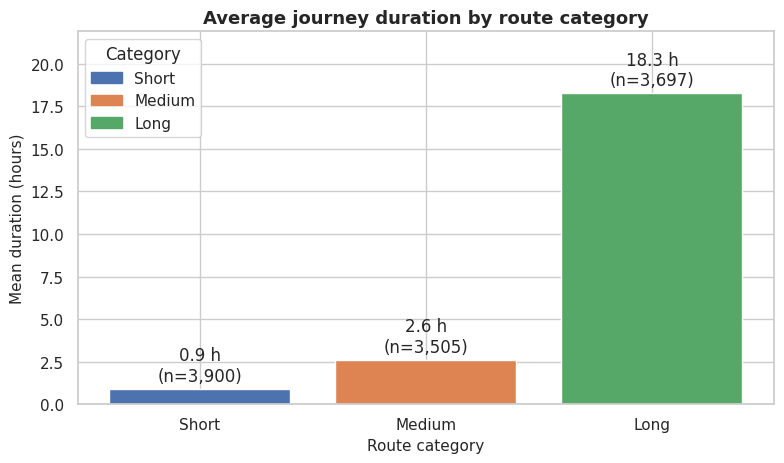

In [16]:
# ============================================================
# CELL 16 – Task 4.1: Average journey duration by route category
# ============================================================
valid_tr = trains[trains["Journey_Valid"] & trains["Route_Category"].isin(CATEGORY_ORDER)].copy()
print(f"Trains used: {len(valid_tr):,} (reliable duration AND classified route) of {len(trains):,}")
if valid_tr.empty:
    raise ValueError("No train has both a reliable duration and a route category – check Level 2 outputs.")

dur_cat = (valid_tr.groupby("Route_Category")["Duration_Hours"]
           .agg(Trains="count", Mean_Hours="mean", Median_Hours="median", Min_Hours="min", Max_Hours="max")
           .reindex(CATEGORY_ORDER).dropna(how="all"))
dur_cat["Mean_Duration"] = (dur_cat["Mean_Hours"] * 3600).apply(fmt_hm)
display(dur_cat)

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(dur_cat.index, dur_cat["Mean_Hours"], color=[CAT_COLORS[c] for c in dur_cat.index])
ax.bar_label(bars, labels=[f"{v:.1f} h\n(n={n:,})" for v, n in zip(dur_cat["Mean_Hours"], dur_cat["Trains"])], padding=3)
ax.set(title="Average journey duration by route category", xlabel="Route category", ylabel="Mean duration (hours)")
ax.set_ylim(0, dur_cat["Mean_Hours"].max() * 1.2)
ax.legend(handles=[Patch(color=CAT_COLORS[c], label=c) for c in dur_cat.index], title="Category")
finish_fig("04_1_avg_duration_by_category")

## Task 4.2 – High-traffic stations
Stations are ranked by **distinct trains** (repeat visits do not inflate the rank).

In [17]:
# ============================================================
# CELL 17 – Task 4.2: Top 10 and Top 20 stations
# ============================================================
total_trains = trains["Train_No"].nunique()
top_cols = ["Station_Name", "Station_Code", "Distinct_Trains", "Total_Occurrences"]
top10 = station_freq.head(10)[top_cols].copy(); top10["% of all trains"] = top10["Distinct_Trains"] / total_trains * 100
top20 = station_freq.head(20)[top_cols].copy(); top20["% of all trains"] = top20["Distinct_Trains"] / total_trains * 100
print("▶ TOP 10 stations by distinct trains"); display(top10)
print("▶ TOP 20 stations by distinct trains"); display(top20)
save_csv(top20, "level4_top20_stations.csv")

▶ TOP 10 stations by distinct trains


,Station_Name,Station_Code,Distinct_Trains,Total_Occurrences,% of all trains
1,CST-MUMBAI,CSMT,1027,1027,9.24
2,KALYAN JN,KYN,828,828,7.45
3,THANE,TNA,796,796,7.16
4,SEALDAH,SDAH,745,745,6.70
5,CHENNAI BEAC,MSB,738,738,6.64
6,HOWRAH JN.,HWH,699,699,6.29
7,DADAR,DR,567,567,5.10
8,DUM DUM JN.,DDJ,463,463,4.17
9,KURLA,CLA,462,462,4.16
10,TAMBARAM,TBM,434,434,3.91


▶ TOP 20 stations by distinct trains


,Station_Name,Station_Code,Distinct_Trains,Total_Occurrences,% of all trains
1,CST-MUMBAI,CSMT,1027,1027,9.24
2,KALYAN JN,KYN,828,828,7.45
3,THANE,TNA,796,796,7.16
4,SEALDAH,SDAH,745,745,6.70
5,CHENNAI BEAC,MSB,738,738,6.64
6,HOWRAH JN.,HWH,699,699,6.29
7,DADAR,DR,567,567,5.10
8,DUM DUM JN.,DDJ,463,463,4.17
9,KURLA,CLA,462,462,4.16
10,TAMBARAM,TBM,434,434,3.91


💾 Saved: outputs/level4_top20_stations.csv  (20 rows)


'outputs/level4_top20_stations.csv'

## Task 4.3 – Visualizations
Six charts: busiest stations, trains by category, duration distribution, average duration by category, station counts per train, and train frequency across stations.

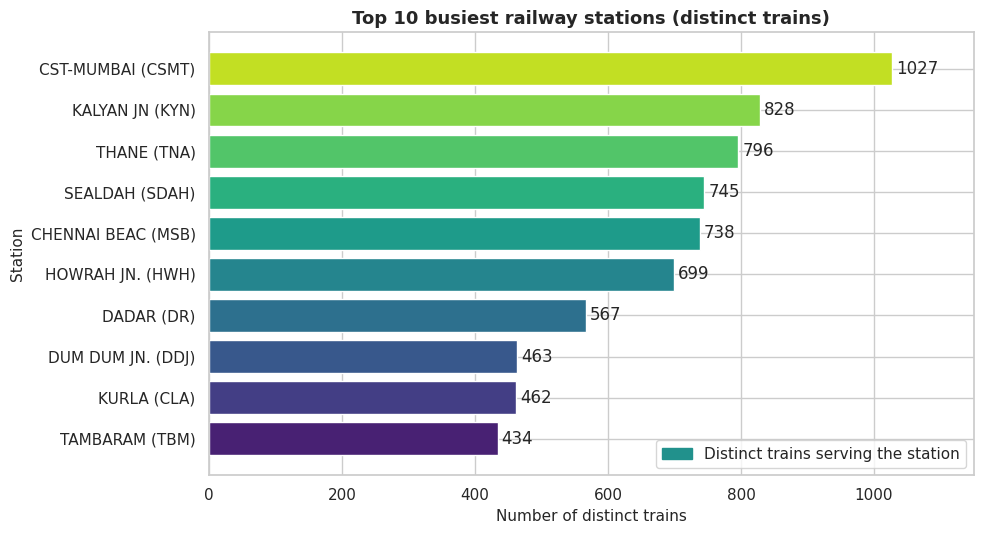

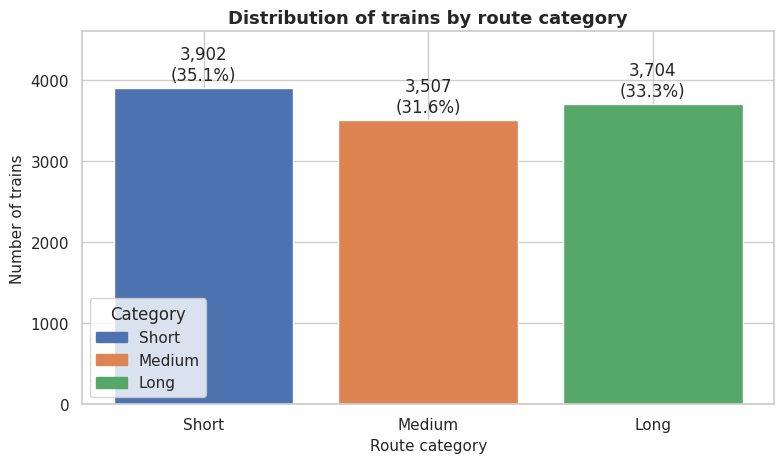

In [18]:
# ============================================================
# CELL 18 – Task 4.3 (charts 1-2): busiest stations, trains per category
# ============================================================
# Chart 1 – Top 10 busiest stations
t10 = station_freq.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(t10["Station_Label"], t10["Distinct_Trains"], color=sns.color_palette("viridis", len(t10)))
ax.bar_label(bars, fmt="%d", padding=3)
ax.set(title="Top 10 busiest railway stations (distinct trains)", xlabel="Number of distinct trains", ylabel="Station")
ax.set_xlim(0, t10["Distinct_Trains"].max() * 1.12)
ax.legend(handles=[Patch(color=sns.color_palette("viridis", 1)[0], label="Distinct trains serving the station")], loc="lower right")
finish_fig("04_3_1_top10_busiest_stations")

# Chart 2 – Trains by route category
cat_counts = trains["Route_Category"].value_counts().reindex(ALL_CATEGORIES, fill_value=0)
cat_counts = cat_counts[(cat_counts > 0) | cat_counts.index.isin(CATEGORY_ORDER)]
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(cat_counts.index, cat_counts.values, color=[CAT_COLORS[c] for c in cat_counts.index])
ax.bar_label(bars, labels=[f"{v:,}\n({v / len(trains):.1%})" for v in cat_counts.values], padding=3)
ax.set(title="Distribution of trains by route category", xlabel="Route category", ylabel="Number of trains")
ax.set_ylim(0, cat_counts.max() * 1.18)
ax.legend(handles=[Patch(color=CAT_COLORS[c], label=c) for c in cat_counts.index], title="Category")
finish_fig("04_3_2_trains_by_route_category")

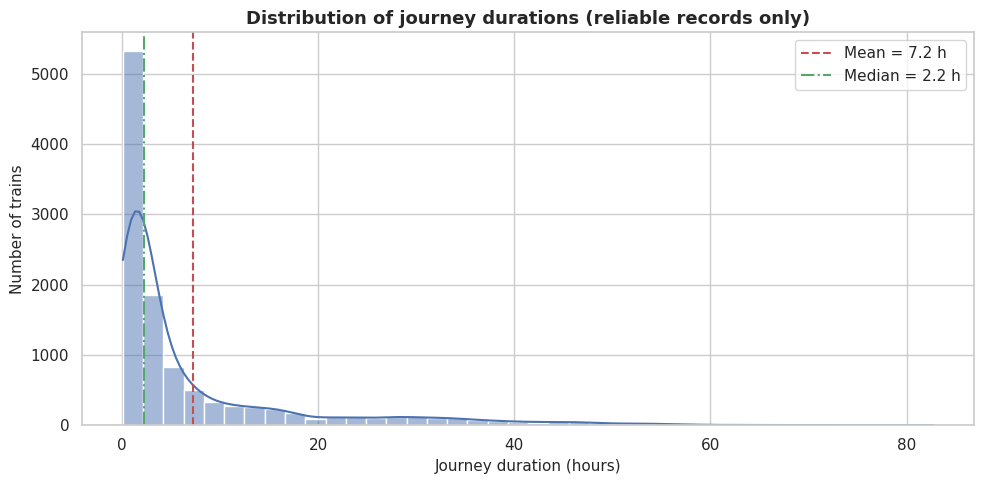

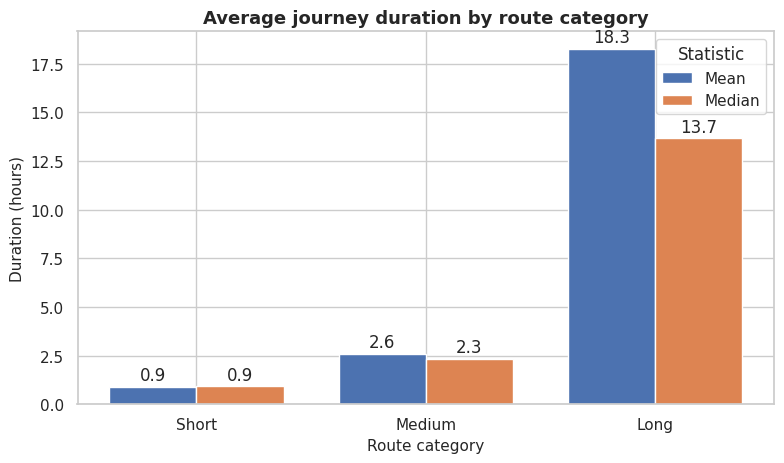

In [19]:
# ============================================================
# CELL 19 – Task 4.3 (charts 3-4): duration distribution and category averages
# ============================================================
# Chart 3 – Journey duration distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(trains.loc[trains["Journey_Valid"], "Duration_Hours"], bins=40, kde=True, color="#4C72B0", ax=ax)
mean_h = trains["Duration_Hours"].mean(); med_h = trains["Duration_Hours"].median()
ax.axvline(mean_h, color="#C44E52", ls="--", label=f"Mean = {mean_h:.1f} h")
ax.axvline(med_h, color="#55A868", ls="-.", label=f"Median = {med_h:.1f} h")
ax.set(title="Distribution of journey durations (reliable records only)", xlabel="Journey duration (hours)", ylabel="Number of trains")
ax.legend(); finish_fig("04_3_3_journey_duration_distribution")

# Chart 4 – Average duration by category (with spread)
fig, ax = plt.subplots(figsize=(8, 4.8))
means = dur_cat["Mean_Hours"]; med = dur_cat["Median_Hours"]
x = np.arange(len(means)); w = 0.38
b1 = ax.bar(x - w / 2, means, w, label="Mean", color="#4C72B0")
b2 = ax.bar(x + w / 2, med, w, label="Median", color="#DD8452")
ax.bar_label(b1, fmt="%.1f", padding=2); ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(means.index)
ax.set(title="Average journey duration by route category", xlabel="Route category", ylabel="Duration (hours)")
ax.legend(title="Statistic"); finish_fig("04_3_4_mean_median_duration_by_category")

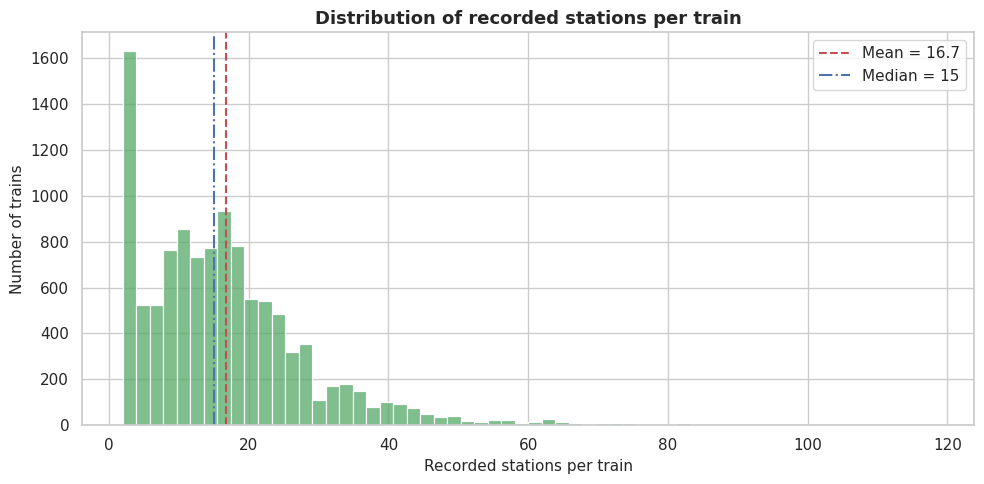

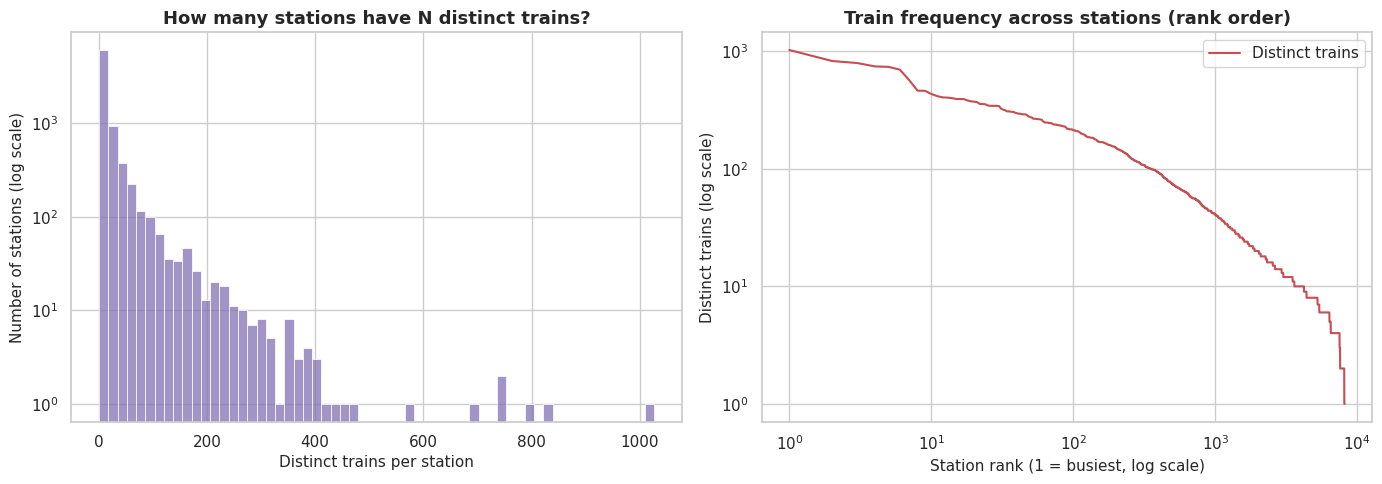

In [20]:
# ============================================================
# CELL 20 – Task 4.3 (charts 5-6): station counts per train, train frequency across stations
# ============================================================
# Chart 5 – Station counts per train
fig, ax = plt.subplots(figsize=(10, 5))
n_bins = int(min(60, max(trains["Total_Recorded_Stations"].nunique(), 5)))
sns.histplot(trains["Total_Recorded_Stations"], bins=n_bins, color="#55A868", ax=ax)
mean_s = trains["Total_Recorded_Stations"].mean(); med_s = trains["Total_Recorded_Stations"].median()
ax.axvline(mean_s, color="#C44E52", ls="--", label=f"Mean = {mean_s:.1f}")
ax.axvline(med_s, color="#4C72B0", ls="-.", label=f"Median = {med_s:.0f}")
ax.set(title="Distribution of recorded stations per train", xlabel="Recorded stations per train", ylabel="Number of trains")
ax.legend(); finish_fig("04_3_5_stations_per_train")

# Chart 6 – Train frequency across stations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(station_freq["Distinct_Trains"], bins=min(60, station_freq["Distinct_Trains"].nunique()), color="#8172B3", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set(title="How many stations have N distinct trains?", xlabel="Distinct trains per station", ylabel="Number of stations (log scale)")
ranks = np.arange(1, len(station_freq) + 1)
axes[1].plot(ranks, station_freq["Distinct_Trains"].to_numpy(), color="#C44E52", label="Distinct trains")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set(title="Train frequency across stations (rank order)", xlabel="Station rank (1 = busiest, log scale)", ylabel="Distinct trains (log scale)")
axes[1].legend(); finish_fig("04_3_6_train_frequency_across_stations")

## Task 4.4 – Key observations
Every sentence below is generated from the computed results, so the values always match the uploaded dataset.

In [21]:
# ============================================================
# CELL 21 – Task 4.4: Key observations (computed values only)
# ============================================================
OBS = []
n_tr = len(trains); n_st = len(station_freq)
OBS.append(f"The dataset describes **{n_tr:,} trains** calling at **{n_st:,} station codes** ({len(df):,} schedule rows).")

mx = trains.loc[trains["Total_Recorded_Stations"].idxmax()]
OBS.append(f"A typical train records **{trains['Total_Recorded_Stations'].median():.0f} stations** (mean {trains['Total_Recorded_Stations'].mean():.1f}); "
           f"the longest-listed train is **{mx['Train_No']}** ({mx['Route']}) with **{int(mx['Total_Recorded_Stations'])} stations**.")

top1 = station_freq.iloc[0]
OBS.append(f"The busiest station is **{top1['Station_Name']} ({top1['Station_Code']})**, served by **{int(top1['Distinct_Trains']):,} distinct trains** "
           f"({top1['Distinct_Trains'] / n_tr:.1%} of all trains).")
top20_share = station_freq.head(20)["Total_Occurrences"].sum() / station_freq["Total_Occurrences"].sum()
OBS.append(f"The 20 busiest stations account for **{top20_share:.1%}** of all station occurrences, so traffic is concentrated in a small set of hubs.")
one_train = int((station_freq["Distinct_Trains"] == 1).sum())
OBS.append(f"**{one_train:,} stations ({one_train / n_st:.1%})** are served by exactly one train; the median station is served by **{station_freq['Distinct_Trains'].median():.0f}** train(s).")

if len(valid_tr):
    OBS.append(f"Reliable journey durations exist for **{len(valid_tr):,} classified trains**; the mean is **{valid_tr['Duration_Hours'].mean():.1f} h** "
               f"(median {valid_tr['Duration_Hours'].median():.1f} h, maximum {fmt_hm(valid_tr['Duration_sec'].max())}).")
    for c in dur_cat.index:
        OBS.append(f"  • {c} routes: mean **{dur_cat.loc[c, 'Mean_Hours']:.1f} h** across {int(dur_cat.loc[c, 'Trains']):,} trains.")
    spd = (valid_tr["Route_Distance"] / valid_tr["Duration_Hours"])
    q1, q3 = spd.quantile([0.25, 0.75]); fence = (q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1))
    n_out = int(((spd < fence[0]) | (spd > fence[1])).sum())
    OBS.append(f"Average end-to-end ratio (distance ÷ duration, halts included) is **{spd.mean():.1f} {DIST_UNIT}/h** "
               f"(median {spd.median():.1f}); **{n_out:,} trains** lie outside the statistical outlier fence "
               f"({fence[0]:.1f} to {fence[1]:.1f} {DIST_UNIT}/h, Q1/Q3 ± 3·IQR) and deserve a data check. "
               f"The unit of `Distance` is not confirmed, so these ratios are only comparable with each other.")

n_bad = int((~trains["Journey_Valid"]).sum())
top_reason = trains.loc[~trains["Journey_Valid"], "Duration_Status"].value_counts()
OBS.append(f"A reliable duration could **not** be computed for **{n_bad:,} trains ({n_bad / n_tr:.1%})**"
           + (f"; the most common reason is '{top_reason.index[0]}' ({int(top_reason.iloc[0]):,})." if n_bad else "."))
OBS.append(f"Route classification thresholds from the data: Short ≤ **{T_SHORT:,.0f} {DIST_UNIT}**, Medium up to **{T_LONG:,.0f} {DIST_UNIT}**, Long above that.")
OBS.append(f"**{int((trains['Repeated_Station_Records'] > 0).sum()):,} trains** repeat at least one station code (kept as legitimate loops), "
           f"and **{int(quality['Flag_SN_Gap'].sum()):,} trains** have gaps in their SN sequence (**{int((~quality['Enquiry_Eligible']).sum()):,}** trains have a critical order problem).")
OBS.append(f"**{int(quality['Flag_Distance_Decreases'].sum()):,} trains** contain a decreasing distance step, and **{int(quality['Flag_Time_Regression'].sum()):,} trains** contain a time regression (their durations are excluded from the duration analysis).")
OBS.append(f"**{int(trains['Overnight'].where(trains['Journey_Valid'], False).sum()):,} reliable journeys cross midnight** and were handled by the rollover logic.")
OBS.append("`Route_Number` has a single value, so it carries no information and was not used for classification.")

display(Markdown("### Key observations\n\n" + "\n".join(f"{i}. {t}" if not t.startswith("  •") else t for i, t in enumerate(OBS, 1))))

### Key observations

1. The dataset describes **11,113 trains** calling at **8,147 station codes** (186,074 schedule rows).
2. A typical train records **15 stations** (mean 16.7); the longest-listed train is **53041** (HOWRAH JN. (HWH) → JAYNAGAR (JYG)) with **118 stations**.
3. The busiest station is **CST-MUMBAI (CSMT)**, served by **1,027 distinct trains** (9.2% of all trains).
4. The 20 busiest stations account for **5.7%** of all station occurrences, so traffic is concentrated in a small set of hubs.
5. **53 stations (0.7%)** are served by exactly one train; the median station is served by **10** train(s).
6. Reliable journey durations exist for **11,102 classified trains**; the mean is **7.2 h** (median 2.2 h, maximum 82 h 45 min).
  • Short routes: mean **0.9 h** across 3,900 trains.
  • Medium routes: mean **2.6 h** across 3,505 trains.
  • Long routes: mean **18.3 h** across 3,697 trains.
10. Average end-to-end ratio (distance ÷ duration, halts included) is **39.6 units/h** (median 37.8); **7 trains** lie outside the statistical outlier fence (-11.1 to 89.5 units/h, Q1/Q3 ± 3·IQR) and deserve a data check. The unit of `Distance` is not confirmed, so these ratios are only comparable with each other.
11. A reliable duration could **not** be computed for **11 trains (0.1%)**; the most common reason is 'Intermediate times inconsistent (1 regression(s))' (6).
12. Route classification thresholds from the data: Short ≤ **49 units**, Medium up to **171 units**, Long above that.
13. **20 trains** repeat at least one station code (kept as legitimate loops), and **5 trains** have gaps in their SN sequence (**0** trains have a critical order problem).
14. **0 trains** contain a decreasing distance step, and **7 trains** contain a time regression (their durations are excluded from the duration analysis).
15. **2,537 reliable journeys cross midnight** and were handled by the rollover logic.
16. `Route_Number` has a single value, so it carries no information and was not used for classification.

# LEVEL 5 – ADVANCED ANALYSIS AND VISUALIZATION

## Task 5.1 – Pivot tables
**Pivot 1** – rows are stations, columns are route categories and every cell is the number of **distinct trains** (`aggfunc="nunique"`) of that category calling at the station. A `Total_Distinct_Trains` column is added. It shows which stations are served mainly by short, medium or long trains.

**Pivot 2** – rows are route categories and the cells summarise train size and duration with `mean`/`median` aggregations.

In [22]:
# ============================================================
# CELL 22 – Task 5.1: Pivot tables
# ============================================================
st_pairs = (df[["Station_Code", "Train_No"]].drop_duplicates()
              .merge(trains[["Train_No", "Route_Category"]], on="Train_No")
              .merge(station_master, on="Station_Code"))
st_pairs["Station_Label"] = st_pairs["Station_Name"] + " (" + st_pairs["Station_Code"] + ")"

pivot_station_cat = st_pairs.pivot_table(index="Station_Label", columns="Route_Category", values="Train_No",
                                         aggfunc="nunique", fill_value=0)
pivot_station_cat = pivot_station_cat.reindex(columns=[c for c in ALL_CATEGORIES if c in pivot_station_cat.columns])
pivot_station_cat["Total_Distinct_Trains"] = pivot_station_cat.sum(axis=1)
pivot_station_cat = pivot_station_cat.sort_values("Total_Distinct_Trains", ascending=False)
print("▶ Pivot 1 – distinct trains per station and route category (top 20)")
display(pivot_station_cat.head(20))
save_csv(pivot_station_cat, "level5_pivot_station_by_category.csv", index=True)

pivot_cat_stats = trains.assign(Trains=1).pivot_table(
    index="Route_Category",
    values=["Trains", "Total_Recorded_Stations", "Route_Distance", "Duration_Hours"],
    aggfunc={"Trains": "sum", "Total_Recorded_Stations": ["mean", "median"],
             "Route_Distance": ["mean", "median"], "Duration_Hours": ["mean", "median"]})
pivot_cat_stats = pivot_cat_stats.reindex([c for c in ALL_CATEGORIES if c in pivot_cat_stats.index])
print("\n▶ Pivot 2 – category-level summary (mean and median)")
display(pivot_cat_stats)

▶ Pivot 1 – distinct trains per station and route category (top 20)


Route_Category,Short,Medium,Long,Total_Distinct_Trains
Station_Label,,,,
CST-MUMBAI (CSMT),780,141,106,1027
KALYAN JN (KYN),397,177,254,828
THANE (TNA),498,138,160,796
SEALDAH (SDAH),343,336,66,745
CHENNAI BEAC (MSB),529,209,0,738
HOWRAH JN. (HWH),155,297,247,699
DADAR (DR),317,138,112,567
DUM DUM JN. (DDJ),184,263,16,463
KURLA (CLA),323,139,0,462


💾 Saved: outputs/level5_pivot_station_by_category.csv  (8,147 rows)

▶ Pivot 2 – category-level summary (mean and median)


Duration_Hours        Route_Distance        Total_Recorded_Stations        Trains
                         mean median           mean median                    mean median    sum
Route_Category                                                                                  
Short                    0.88   0.92          28.62  29.00                    8.05   6.00   3902
Medium                   2.60   2.33          92.83  87.00                   17.03  17.00   3507
Long                    18.26  13.67         928.05 642.50                   25.63  22.00   3704

## Task 5.2 – Cross-tabulations
All cross-tabs count **distinct (station, train) pairs**, so repeated visits and the constant `Route_Number` column cannot distort them.

1. **Station × route category** for the 25 busiest stations (counts and row percentages).
2. **Route category × train size** (recorded stations per train in quartile bands).
3. **Station traffic tier × route category**. Stations are split into Low / Medium / High traffic *tiers of equal size* by their rank in distinct-train frequency; this shows whether long routes are served mostly by busy hubs.

In [23]:
# ============================================================
# CELL 23 – Task 5.2: Cross-tabulations
# ============================================================
top25_labels = pivot_station_cat.head(25).index
ct_station_cat = pd.crosstab(st_pairs.loc[st_pairs["Station_Label"].isin(top25_labels), "Station_Label"],
                             st_pairs.loc[st_pairs["Station_Label"].isin(top25_labels), "Route_Category"])
ct_station_cat = ct_station_cat.reindex(top25_labels)[[c for c in ALL_CATEGORIES if c in ct_station_cat.columns]]
ct_station_pct = ct_station_cat.div(ct_station_cat.sum(axis=1), axis=0) * 100
print("▶ Cross-tab 1a – top 25 stations × route category (distinct trains)"); display(ct_station_cat)
print("▶ Cross-tab 1b – same, as % of each station's trains"); display(ct_station_pct.round(1))

band = pd.qcut(trains["Total_Recorded_Stations"], q=4, duplicates="drop")
ct_cat_size = pd.crosstab(trains["Route_Category"], band.astype(str), margins=True, margins_name="Total")
print("\n▶ Cross-tab 2 – route category × recorded stations per train (quartile bands)"); display(ct_cat_size)

tier_labels = ["Low-traffic", "Medium-traffic", "High-traffic"]
tier_of_station = pd.qcut(station_freq["Distinct_Trains"].rank(method="first"), 3, labels=tier_labels)
tier_map = pd.Series(tier_of_station.to_numpy(), index=station_freq["Station_Code"].to_numpy())
st_pairs["Traffic_Tier"] = st_pairs["Station_Code"].map(tier_map)
ct_tier_cat = pd.crosstab(st_pairs["Traffic_Tier"], st_pairs["Route_Category"], margins=True, margins_name="Total")
ct_tier_cat = ct_tier_cat.reindex(tier_labels + ["Total"])
ct_tier_pct = pd.crosstab(st_pairs["Route_Category"], st_pairs["Traffic_Tier"], normalize="index").reindex(
    [c for c in ALL_CATEGORIES if c in st_pairs["Route_Category"].unique()])[tier_labels] * 100
print("\n▶ Cross-tab 3a – station traffic tier × route category (station-train pairs)"); display(ct_tier_cat)
print("▶ Cross-tab 3b – % of each category's station visits falling in each traffic tier"); display(ct_tier_pct.round(1))

▶ Cross-tab 1a – top 25 stations × route category (distinct trains)


Route_Category,Short,Medium,Long
Station_Label,,,
CST-MUMBAI (CSMT),780,141,106
KALYAN JN (KYN),397,177,254
THANE (TNA),498,138,160
SEALDAH (SDAH),343,336,66
CHENNAI BEAC (MSB),529,209,0
HOWRAH JN. (HWH),155,297,247
DADAR (DR),317,138,112
DUM DUM JN. (DDJ),184,263,16
KURLA (CLA),323,139,0


▶ Cross-tab 1b – same, as % of each station's trains


Route_Category,Short,Medium,Long
Station_Label,,,
CST-MUMBAI (CSMT),75.90,13.70,10.30
KALYAN JN (KYN),47.90,21.40,30.70
THANE (TNA),62.60,17.30,20.10
SEALDAH (SDAH),46.00,45.10,8.90
CHENNAI BEAC (MSB),71.70,28.30,0.00
HOWRAH JN. (HWH),22.20,42.50,35.30
DADAR (DR),55.90,24.30,19.80
DUM DUM JN. (DDJ),39.70,56.80,3.50
KURLA (CLA),69.90,30.10,0.00



▶ Cross-tab 2 – route category × recorded stations per train (quartile bands)


Total_Recorded_Stations,"(1.999, 8.0]","(15.0, 22.0]","(22.0, 118.0]","(8.0, 15.0]",Total
Route_Category,,,,,
Long,272,782,1824,826,3704
Medium,442,1067,884,1114,3507
Short,2319,738,11,834,3902
Total,3033,2587,2719,2774,11113



▶ Cross-tab 3a – station traffic tier × route category (station-train pairs)


Route_Category,Long,Medium,Short,Total
Traffic_Tier,,,,
Low-traffic,6709,4367,502,11578
Medium-traffic,13607,11630,1606,26843
High-traffic,74598,43736,29289,147623
Total,94914,59733,31397,186044


▶ Cross-tab 3b – % of each category's station visits falling in each traffic tier


Traffic_Tier,Low-traffic,Medium-traffic,High-traffic
Route_Category,,,
Short,1.60,5.10,93.30
Medium,7.30,19.50,73.20
Long,7.10,14.30,78.60


## Task 5.3 – Comparative visualizations
Charts built from the pivot tables and cross-tabulations: stacked station distribution, station × category heat map, top stations within each category, a route-category comparison (stations per train, duration, distance vs duration) and the traffic-tier pattern.

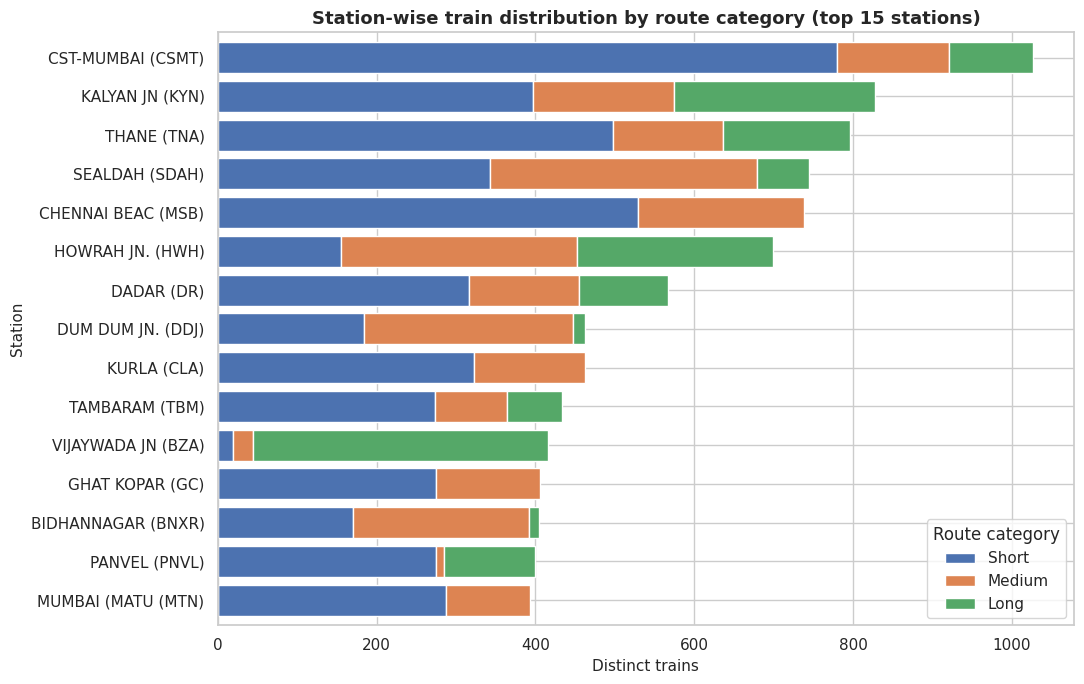

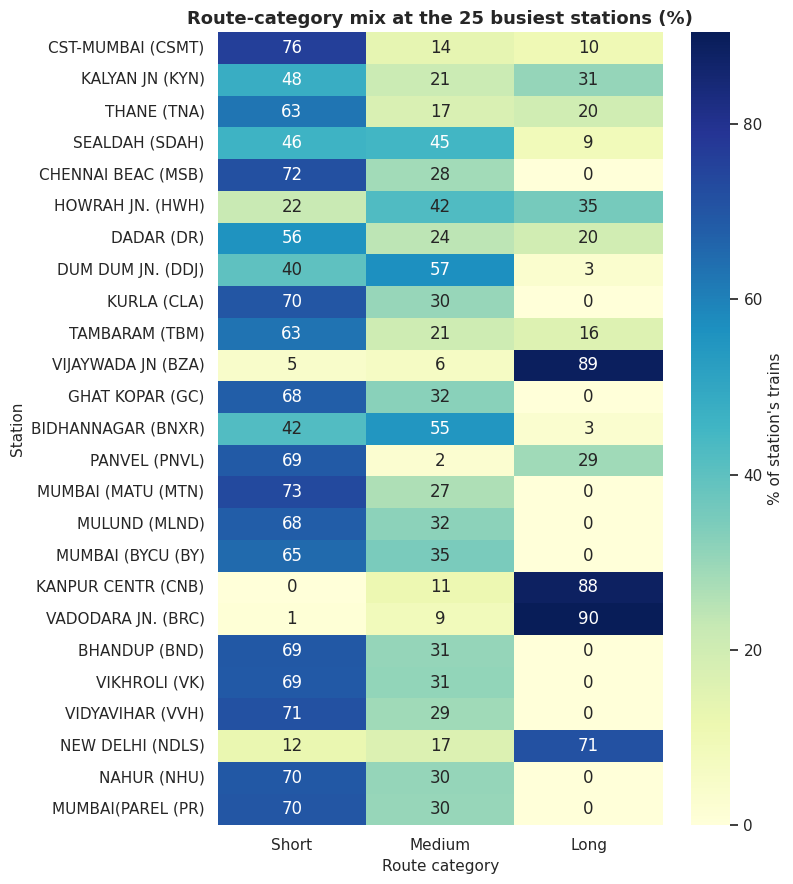

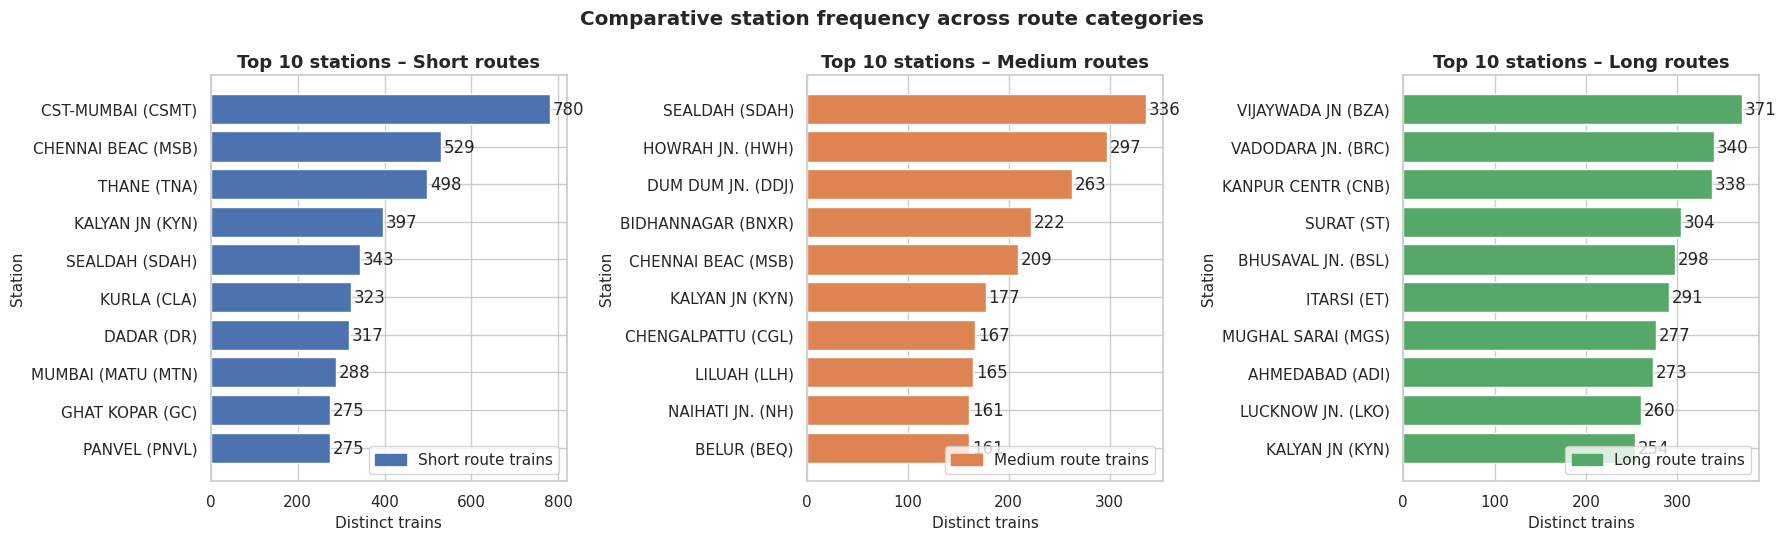

In [24]:
# ============================================================
# CELL 24 – Task 5.3 (charts A-C): station-wise and comparative station frequency
# ============================================================
present_cats = [c for c in ALL_CATEGORIES if c in pivot_station_cat.columns]

# A – stacked bar: station-wise train distribution
top15 = pivot_station_cat.head(15)[present_cats].iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
top15.plot(kind="barh", stacked=True, ax=ax, color=[CAT_COLORS[c] for c in present_cats], width=0.8)
ax.set(title="Station-wise train distribution by route category (top 15 stations)", xlabel="Distinct trains", ylabel="Station")
ax.legend(title="Route category", loc="lower right"); finish_fig("05_3_a_station_distribution_stacked")

# B – heat map: share of each station's trains per category
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(ct_station_pct, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of station's trains"}, ax=ax)
ax.set(title="Route-category mix at the 25 busiest stations (%)", xlabel="Route category", ylabel="Station")
finish_fig("05_3_b_station_category_heatmap")

# C – comparative station frequency: top 10 stations inside each category
cats_to_plot = [c for c in CATEGORY_ORDER if c in pivot_station_cat.columns]
fig, axes = plt.subplots(1, len(cats_to_plot), figsize=(6 * len(cats_to_plot), 5.5), squeeze=False)
for ax, c in zip(axes[0], cats_to_plot):
    t = pivot_station_cat[c].nlargest(10).iloc[::-1]
    bars = ax.barh(t.index, t.values, color=CAT_COLORS[c])
    ax.bar_label(bars, fmt="%d", padding=2)
    ax.set(title=f"Top 10 stations – {c} routes", xlabel="Distinct trains", ylabel="Station")
    ax.legend(handles=[Patch(color=CAT_COLORS[c], label=f"{c} route trains")], loc="lower right")
fig.suptitle("Comparative station frequency across route categories", fontweight="bold")
finish_fig("05_3_c_top_stations_per_category")

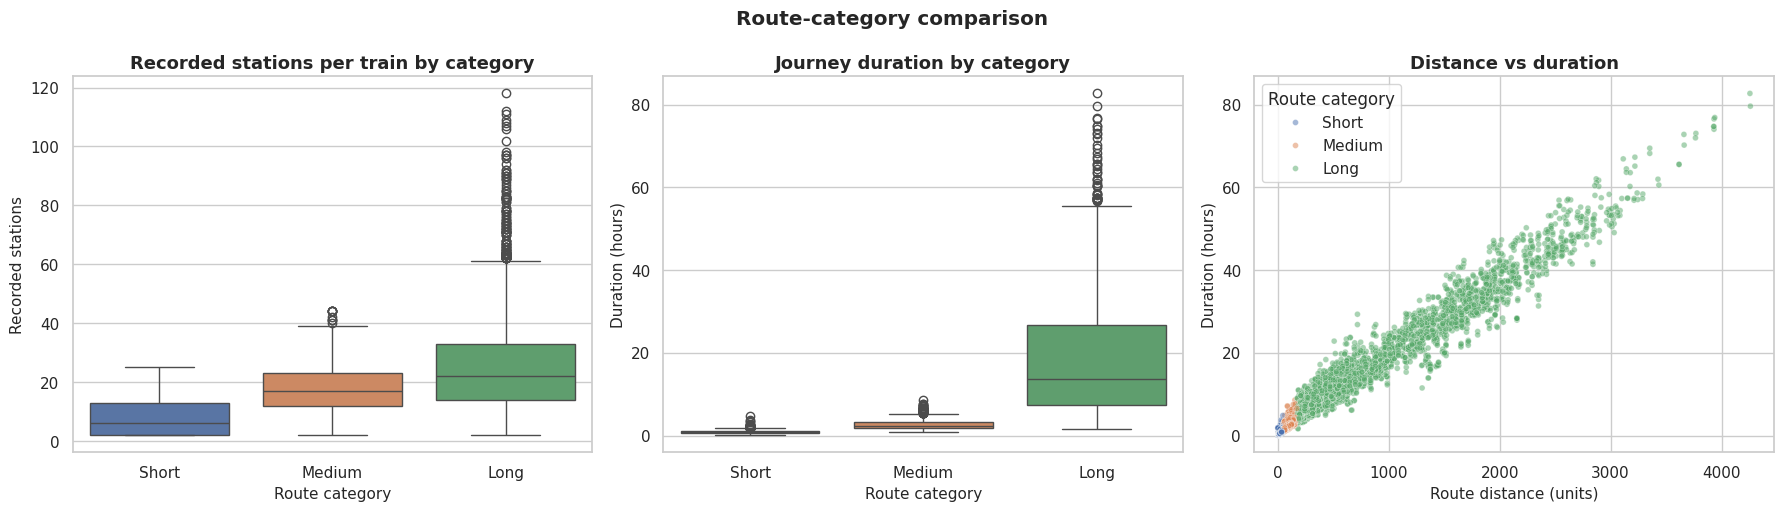

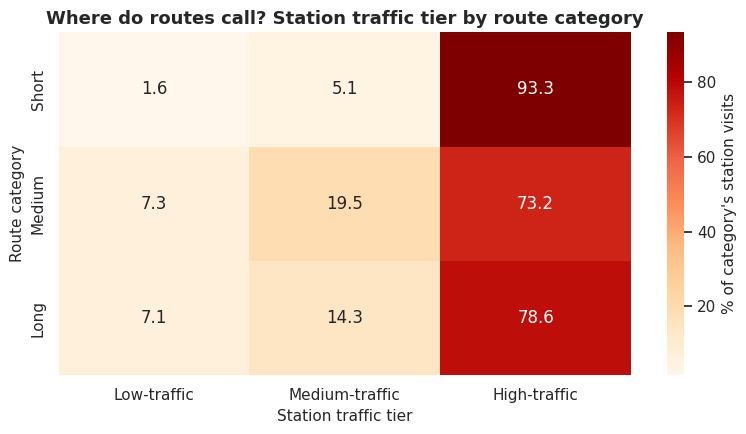

In [25]:
# ============================================================
# CELL 25 – Task 5.3 (charts D-F): route-category comparison and traffic-tier pattern
# ============================================================
plot_cats = [c for c in CATEGORY_ORDER if c in trains["Route_Category"].unique()]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
sns.boxplot(data=trains[trains["Route_Category"].isin(plot_cats)], x="Route_Category", y="Total_Recorded_Stations",
            order=plot_cats, palette=[CAT_COLORS[c] for c in plot_cats], ax=axes[0])
axes[0].set(title="Recorded stations per train by category", xlabel="Route category", ylabel="Recorded stations")
sns.boxplot(data=valid_tr, x="Route_Category", y="Duration_Hours", order=plot_cats,
            palette=[CAT_COLORS[c] for c in plot_cats], ax=axes[1])
axes[1].set(title="Journey duration by category", xlabel="Route category", ylabel="Duration (hours)")
sns.scatterplot(data=valid_tr, x="Route_Distance", y="Duration_Hours", hue="Route_Category", hue_order=plot_cats,
                palette=CAT_COLORS, alpha=0.5, s=18, ax=axes[2])
axes[2].set(title="Distance vs duration", xlabel=f"Route distance ({DIST_UNIT})", ylabel="Duration (hours)")
axes[2].legend(title="Route category")
fig.suptitle("Route-category comparison", fontweight="bold"); finish_fig("05_3_d_route_category_comparison")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(ct_tier_pct, annot=True, fmt=".1f", cmap="OrRd", cbar_kws={"label": "% of category's station visits"}, ax=ax)
ax.set(title="Where do routes call? Station traffic tier by route category", xlabel="Station traffic tier", ylabel="Route category")
finish_fig("05_3_e_traffic_tier_heatmap")

## Task 5.4 – Advanced insights
Evidence-based conclusions on important stations, train distribution and route-length patterns, generated from the tables above.

In [26]:
# ============================================================
# CELL 26 – Task 5.4: Advanced insights (computed)
# ============================================================
INS = []
hub_cut = station_freq["Distinct_Trains"].quantile(0.99)
hubs = station_freq[station_freq["Distinct_Trains"] >= hub_cut]
INS.append(f"**Important stations.** The top 1 % of stations (≥ {hub_cut:.0f} distinct trains) number **{len(hubs):,}**; the five busiest are "
           + ", ".join(f"{r.Station_Label} ({r.Distinct_Trains:,})" for r in hubs.head(5).itertuples()) + ".")
INS.append(f"**Distribution pattern.** Mean frequency is **{station_freq['Distinct_Trains'].mean():.1f}** trains per station but the median is only "
           f"**{station_freq['Distinct_Trains'].median():.0f}**; **{(station_freq['Distinct_Trains'] <= 2).mean():.1%}** of stations are served by 2 trains or fewer. "
           "A mean far above the median confirms a heavily skewed (hub-and-spoke) pattern.")
for c in [c for c in CATEGORY_ORDER if c in ct_tier_pct.index]:
    INS.append(f"**{c} routes:** {ct_tier_pct.loc[c, 'High-traffic']:.1f}% of their station visits are at high-traffic stations "
               f"and {ct_tier_pct.loc[c, 'Low-traffic']:.1f}% at low-traffic stations.")
if len(valid_tr) > 2:
    corr = valid_tr[["Route_Distance", "Duration_Hours", "Total_Recorded_Stations"]].corr(method="spearman")
    INS.append(f"**Route-length pattern.** Spearman correlation: distance vs duration = **{corr.loc['Route_Distance', 'Duration_Hours']:.2f}**, "
               f"distance vs recorded stations = **{corr.loc['Route_Distance', 'Total_Recorded_Stations']:.2f}**.")
    sp = (valid_tr["Route_Distance"] / valid_tr["Duration_Hours"]).groupby(valid_tr["Route_Category"]).median().reindex(CATEGORY_ORDER).dropna()
    INS.append(f"**Distance ÷ duration by category (median, {DIST_UNIT}/h):** " + ", ".join(f"{k} = {v:.1f}" for k, v in sp.items()) + ".")
stops_by_cat = trains.groupby("Route_Category")["Total_Recorded_Stations"].median().reindex(CATEGORY_ORDER).dropna()
INS.append("**Median recorded stations by category:** " + ", ".join(f"{k} = {v:.0f}" for k, v in stops_by_cat.items()) + ".")
best = pivot_station_cat.head(1)
INS.append(f"**Conclusion.** {best.index[0]} is the dominant station with {int(best['Total_Distinct_Trains'].iloc[0]):,} trains; "
           f"the distinct-train count and the occurrence count differ for {int((station_freq['Repeat_Visits'] > 0).sum()):,} stations because of repeated visits.")
display(Markdown("### Advanced insights\n\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(INS, 1))))

### Advanced insights

1. **Important stations.** The top 1 % of stations (≥ 233 distinct trains) number **83**; the five busiest are CST-MUMBAI (CSMT) (1,027), KALYAN JN (KYN) (828), THANE (TNA) (796), SEALDAH (SDAH) (745), CHENNAI BEAC (MSB) (738).
2. **Distribution pattern.** Mean frequency is **22.8** trains per station but the median is only **10**; **7.1%** of stations are served by 2 trains or fewer. A mean far above the median confirms a heavily skewed (hub-and-spoke) pattern.
3. **Short routes:** 93.3% of their station visits are at high-traffic stations and 1.6% at low-traffic stations.
4. **Medium routes:** 73.2% of their station visits are at high-traffic stations and 7.3% at low-traffic stations.
5. **Long routes:** 78.6% of their station visits are at high-traffic stations and 7.1% at low-traffic stations.
6. **Route-length pattern.** Spearman correlation: distance vs duration = **0.98**, distance vs recorded stations = **0.64**.
7. **Distance ÷ duration by category (median, units/h):** Short = 33.8, Medium = 36.7, Long = 49.4.
8. **Median recorded stations by category:** Short = 6, Medium = 17, Long = 22.
9. **Conclusion.** CST-MUMBAI (CSMT) is the dominant station with 1,027 trains; the distinct-train count and the occurrence count differ for 15 stations because of repeated visits.

# LEVEL 6 – FINAL CAPSTONE: INTERACTIVE TRAIN ROUTE ENQUIRY SYSTEM

### Design
* Uses the **cleaned, ordered** data. Only trains with a trustworthy order are searchable (no 🔴 critical issue: duplicate/blank `SN`, fewer than 2 records). Trains with 🟠 warnings stay searchable, and the warning appears in the results **only when it touches the stretch searched**.
* **Direct train** = a train that calls at the source and later at the destination (`Stop_Pos(destination) > Stop_Pos(source)`). If a looping train passes a station twice, **every** valid pairing is listed (no visit is discarded).
* **Duration** = destination arrival − source departure on the unrolled timeline from Task 2.2, so overnight journeys are right.
* **Station input** accepts a station **code** (`NDLS`), an **exact name**, or a **partial name/code**. If a query matches up to `MAX_AMBIGUOUS_MATCHES` stations, every combination is searched and the matches are listed. If it matches more, the user is asked to refine and candidates are shown. Unknown inputs get "did you mean" suggestions.
* Results can be sorted by departure time or by journey duration. **All** matches are available: the screen is paginated and the full list (with every intermediate station) can be exported to CSV.
* **Static timetable only** – no live status, delays or real-time API.

In [27]:
# ============================================================
# CELL 27 – Level 6, part 1: enquiry engine (data structures + search logic)
# ============================================================
import ipywidgets as widgets

ENQ_COLS = ["Train_No", "Stop_Pos", "Station_Code", "Station_Name", "Distance", "Arr_sec", "Dep_sec",
            "Arr_abs", "Dep_abs", "SN_Gap_Before", "Dist_Decrease_Before", "Time_Regression"]
# Only trains whose station ORDER is trustworthy (no critical issue) are searchable.
enq = (df[df["Enquiry_Eligible"]][ENQ_COLS]
         .sort_values(["Train_No", "Stop_Pos"], kind="mergesort").reset_index(drop=True))
# Running counters let us ask "did a problem occur between stop A and stop B?" with one subtraction.
for flag, cum in [("SN_Gap_Before", "cumGap"), ("Dist_Decrease_Before", "cumDec"), ("Time_Regression", "cumReg")]:
    enq[cum] = enq.groupby("Train_No")[flag].cumsum().astype(int)
train_idx = enq.groupby("Train_No", sort=False).indices            # train -> row positions in route order
train_warn_map = quality.set_index("Train_No")["Warning_Issues"].to_dict()

enq_stations = station_master[station_master["Station_Code"].isin(enq["Station_Code"].unique())].copy()
enq_stations["_name_u"] = enq_stations["Station_Name"].str.upper()
enq_stations["Label"] = enq_stations["Station_Code"] + " – " + enq_stations["Station_Name"]
code_set = set(enq_stations["Station_Code"])
code_to_name = dict(zip(enq_stations["Station_Code"], enq_stations["Station_Name"]))
name_to_codes = enq_stations.groupby("_name_u")["Station_Code"].apply(list).to_dict()
all_names_u = list(name_to_codes.keys())

def resolve_station(query):
    """Turn user text into station codes. Accepts a code, an exact name, or part of a name/code."""
    q = (query or "").strip()
    if " – " in q:                                   # value picked from the drop-down suggestions
        q = q.split(" – ")[0].strip()
    if not q:
        return [], "empty"
    qu = q.upper()
    if qu in code_set:
        return [qu], "code"
    if qu in name_to_codes:
        return list(name_to_codes[qu]), "name"
    pat = re.escape(qu)
    mask = enq_stations["_name_u"].str.contains(pat, regex=True) | enq_stations["Station_Code"].str.contains(pat, regex=True)
    return enq_stations.loc[mask, "Station_Code"].tolist(), "partial"

def check_side(text, label):
    """Validate one input box. Returns (codes, status, message) with status ok / invalid / ambiguous."""
    codes, how = resolve_station(text)
    if how == "empty":
        return codes, "invalid", f"Please enter a {label} station (code, name or part of a name)."
    if not codes:
        sugg = difflib.get_close_matches((text or "").strip().upper(), all_names_u, n=5, cutoff=0.6)
        hint = f" Did you mean: {', '.join(s.title() for s in sugg)}?" if sugg else ""
        return codes, "invalid", f"'{text}' does not match any {label} station in the dataset.{hint}"
    if len(codes) > MAX_AMBIGUOUS_MATCHES:
        cand = ", ".join(f"{c} – {code_to_name[c]}" for c in codes[:15])
        return codes, "ambiguous", (f"'{text}' matches {len(codes)} {label} stations – please be more specific "
                                    f"or use a station code. Examples: {cand}{' …' if len(codes) > 15 else ''}")
    note = ""
    if len(codes) > 1:
        note = f"'{text}' matches {len(codes)} {label} stations: " + "; ".join(f"{c} – {code_to_name[c]}" for c in codes) + "."
    return codes, "ok", note

def stops_between(train_no, src_pos, dst_pos):
    """ALL rows of a train from the source stop to the destination stop (inclusive), in route order."""
    idx = train_idx[train_no]
    return enq.iloc[idx[src_pos - 1:dst_pos]]

def find_direct(src_codes, dst_codes):
    """Every (source visit, later destination visit) pair on the same train. A looping train that passes a
    station twice therefore yields every valid pairing – no legitimate visit is discarded."""
    keep = ["Train_No", "Stop_Pos", "Station_Code", "Station_Name", "Distance", "cumGap", "cumDec", "cumReg"]
    S = enq.loc[enq["Station_Code"].isin(src_codes), keep + ["Dep_sec", "Dep_abs"]]
    D = enq.loc[enq["Station_Code"].isin(dst_codes), keep + ["Arr_sec", "Arr_abs"]]
    m = S.merge(D, on="Train_No", suffixes=("_src", "_dst"))
    m = m[m["Stop_Pos_dst"] > m["Stop_Pos_src"]].copy()           # destination must come AFTER the source
    m["Gap"] = m["Stop_Pos_dst"] - m["Stop_Pos_src"]
    return m

def enquire(source_text, destination_text, sort_by="Departure time"):
    """Run one enquiry. Returns a dict: status, message, notes, table (ALL matches), n_rows, n_trains."""
    res = {"status": "ok", "message": "", "notes": [], "table": pd.DataFrame(), "n_rows": 0, "n_trains": 0,
           "source": source_text, "destination": destination_text}
    s_codes, s_stat, s_msg = check_side(source_text, "source")
    d_codes, d_stat, d_msg = check_side(destination_text, "destination")
    for stat, msg in ((s_stat, s_msg), (d_stat, d_msg)):
        if stat != "ok":
            res.update(status=stat, message=msg)
            return res
    res["notes"] = [n for n in (s_msg, d_msg) if n]
    if set(s_codes) == set(d_codes) and len(s_codes) == 1:
        res.update(status="same", message="Source and destination are the same station. Please choose two different stations.")
        return res

    m = find_direct(s_codes, d_codes)
    if m.empty:
        rev = find_direct(d_codes, s_codes)
        extra = (f" Note: {rev['Train_No'].nunique():,} train(s) run in the opposite direction "
                 f"({', '.join(d_codes[:3])} → {', '.join(s_codes[:3])}).") if len(rev) else ""
        res.update(status="no_direct", message="No direct train was found between the selected stations in the dataset." + extra)
        return res

    # --- duration on the unrolled timeline (handles midnight; no dates are invented) ---
    dur_s = m["Arr_abs"] - m["Dep_abs"]
    m["Duration_sec"] = dur_s.where(dur_s > 0)
    day_off = np.floor(m["Arr_abs"] / 86400) - np.floor(m["Dep_abs"] / 86400)
    m["Arrival_Day"] = np.where(day_off.isna(), "N/A",
                                np.where(day_off <= 0, "Same day", "+" + day_off.fillna(0).astype(int).astype(str) + " day(s)"))
    # --- warnings that touch ONLY the searched stretch ---
    seg_gap = (m["cumGap_dst"] - m["cumGap_src"]) > 0
    seg_dec = (m["cumDec_dst"] - m["cumDec_src"]) > 0
    seg_reg = (m["cumReg_dst"] - m["cumReg_src"]) > 0
    dist = m["Distance_dst"] - m["Distance_src"]
    m["Distance_Seg"] = dist.where((dist >= 0) & ~seg_dec)                  # never show a distance across a decreasing step
    m["Intermediate_Stops"] = m["Gap"] - 1
    m["Departs"] = seconds_to_hms(m["Dep_sec"]).fillna("N/A")
    m["Arrives"] = seconds_to_hms(m["Arr_sec"]).fillna("N/A")
    m["Duration"] = m["Duration_sec"].apply(fmt_hm)
    m["Duration_Check"] = seg_reg | m["Duration_sec"].isna()
    m.loc[seg_reg & m["Duration_sec"].notna(), "Duration"] += " ⚠"
    warn = pd.DataFrame({
        "a": np.where(seg_gap, "SN gap inside this stretch – some stations may be missing; ", ""),
        "b": np.where(seg_dec, "distance decreases inside this stretch – distance not shown; ", ""),
        "c": np.where(seg_reg, "schedule times go backwards inside this stretch – duration is doubtful; ", ""),
        "d": np.where(m["Duration_sec"].isna() & ~seg_reg, "a departure/arrival time is missing – duration not available; ", "")})
    m["Warnings"] = (warn["a"] + warn["b"] + warn["c"] + warn["d"]).str.rstrip("; ")
    m["Train_Warnings"] = m["Train_No"].map(train_warn_map).fillna("")

    m = m.sort_values(["Duration_sec", "Dep_sec"] if sort_by == "Journey duration" else ["Dep_sec", "Duration_sec"],
                      na_position="last").reset_index(drop=True)
    res["table"], res["n_rows"], res["n_trains"] = m, len(m), int(m["Train_No"].nunique())
    msg = f"Found {res['n_trains']:,} direct train(s)"
    msg += f" ({res['n_rows']:,} source→destination pairings, because some trains pass a station more than once)." if res["n_rows"] != res["n_trains"] else "."
    if m["Duration_sec"].notna().any():
        best = m.loc[m["Duration_sec"].idxmin()]
        msg += f" Fastest: train {best['Train_No']} in {best['Duration']}."
    n_warn = int((m["Warnings"] != "").sum())
    if n_warn:
        msg += f" ⚠ {n_warn:,} result(s) carry a data warning (see the Warnings column)."
    res["message"] = msg
    return res

def paginate(table, page, page_size):
    """Return (rows_of_this_page, total_pages, page_used). Every row belongs to exactly one page."""
    n_pages = max(1, int(np.ceil(len(table) / page_size)))
    page = min(max(1, page), n_pages)
    return table.iloc[(page - 1) * page_size: page * page_size], n_pages, page

def build_export(res):
    """Complete result table (ALL matches) with the full list of intermediate stations, ready for CSV."""
    t = res["table"]
    via = ["  >  ".join(stops_between(tn, a, b)["Station_Name"].iloc[1:-1])
           for tn, a, b in zip(t["Train_No"], t["Stop_Pos_src"], t["Stop_Pos_dst"])]
    return pd.DataFrame({
        "Train_No": t["Train_No"], "Source_Code": t["Station_Code_src"], "Source_Station": t["Station_Name_src"],
        "Destination_Code": t["Station_Code_dst"], "Destination_Station": t["Station_Name_dst"],
        "Departure": t["Departs"], "Arrival": t["Arrives"], "Arrival_Day": t["Arrival_Day"],
        "Duration": t["Duration"], "Duration_Hours": t["Duration_sec"] / 3600,
        f"Distance_{DIST_UNIT}": t["Distance_Seg"], "Intermediate_Stops": t["Intermediate_Stops"],
        "Intermediate_Stations": via, "Warnings": t["Warnings"], "Train_Warnings": t["Train_Warnings"]})

def detail_frame(row):
    """Every station between source and destination (inclusive) for one result row – nothing truncated."""
    stops = stops_between(row["Train_No"], int(row["Stop_Pos_src"]), int(row["Stop_Pos_dst"])).copy()
    stops["Role"] = "Intermediate"
    stops.iloc[0, stops.columns.get_loc("Role")] = "Source"
    stops.iloc[-1, stops.columns.get_loc("Role")] = "Destination"
    stops["Arrival"] = seconds_to_hms(stops["Arr_sec"]).fillna("—")
    stops["Departure"] = seconds_to_hms(stops["Dep_sec"]).fillna("—")
    stops[f"{DIST_UNIT} from source"] = stops["Distance"] - stops["Distance"].iloc[0]
    return stops[["Stop_Pos", "Role", "Station_Name", "Station_Code", "Arrival", "Departure", f"{DIST_UNIT} from source"]]\
        .rename(columns={"Stop_Pos": "Stop #", "Station_Name": "Station", "Station_Code": "Code"})

print(f"✅ Enquiry engine ready: {enq['Train_No'].nunique():,} searchable trains, {len(enq_stations):,} searchable stations.")
excluded_n = int((~quality['Enquiry_Eligible']).sum())
if excluded_n:
    print(f"ℹ {excluded_n:,} train(s) are NOT searchable because their station order is unreliable (listed in excluded_from_enquiry.csv).")

✅ Enquiry engine ready: 11,113 searchable trains, 8,147 searchable stations.


### Level 6, part 2 – the interactive interface
**Cell 28** builds the widget: title, source and destination boxes (type or pick; codes, names and partial names work), a sort option, a **Search** button, a **paginated** results table with the true total (`Showing 1–25 of N`), **Previous / Next** buttons, an **Export ALL results (CSV)** button, and a train selector whose details list **every** intermediate station between the chosen stations. It is pre-filled with a real route taken from the dataset, so results appear immediately; change the boxes and press **Search trains** for your own enquiry.

In [28]:
# ============================================================
# CELL 28 – Level 6, part 2: ipywidgets interface (paginated, exportable)
# ============================================================
ENQ_CSS = ("<style>table.enq{border-collapse:collapse;font-size:13px}"
           "table.enq th{background:#1f3b63;color:#fff;padding:6px 10px;text-align:left;position:sticky;top:0}"
           "table.enq td{padding:5px 10px;border-bottom:1px solid #ddd;color:#222;background:#fff}"
           "table.enq tr:hover td{background:#eaf1fb}"
           ".enq-scroll{max-height:420px;overflow:auto;border:1px solid #ddd}"
           ".enq-msg{padding:8px 12px;border-radius:6px;margin:6px 0;font-size:14px}</style>")

def html_table(frame, scroll=False):
    """Render a DataFrame as HTML. NO row limit: every row passed in is shown (scrollable for long lists)."""
    body = frame.to_html(index=False, border=0, classes="enq", na_rep="N/A", float_format=lambda v: f"{v:,.1f}", escape=True)
    return ENQ_CSS + (f"<div class='enq-scroll'>{body}</div>" if scroll else body)

def msg_box(text, kind="info"):
    colors = {"info": "#e8f1fb", "ok": "#e6f4ea", "warn": "#fff4e0", "err": "#fde8e8"}
    return HTML(ENQ_CSS + f"<div class='enq-msg' style='background:{colors[kind]};color:#222'>{text}</div>")

state = {"result": None, "page": 1, "muted": False}

title_w = widgets.HTML("<h2 style='margin-bottom:2px'>🚆 Train Route Enquiry System</h2>"
                       "<div style='color:#666'>Static timetable lookup built from <b>Dataset1.csv</b>. "
                       "No live running status, delays or real-time railway data.</div>")
opts = tuple(enq_stations["Label"].tolist())
box_layout = widgets.Layout(width="520px")
src_w = widgets.Combobox(placeholder="Type a station code, name or part of a name", options=opts, ensure_option=False,
                         description="From:", layout=box_layout, style={"description_width": "90px"})
dst_w = widgets.Combobox(placeholder="Type a station code, name or part of a name", options=opts, ensure_option=False,
                         description="To:", layout=box_layout, style={"description_width": "90px"})
sort_w = widgets.Dropdown(options=["Departure time", "Journey duration"], value="Departure time",
                          description="Sort by:", style={"description_width": "90px"})
size_w = widgets.Dropdown(options=[10, 25, 50, 100, 250], value=RESULTS_PAGE_SIZE if RESULTS_PAGE_SIZE in (10, 25, 50, 100, 250) else 25,
                          description="Per page:", style={"description_width": "70px"}, layout=widgets.Layout(width="170px"))
search_btn = widgets.Button(description="Search trains", button_style="primary", icon="search")
swap_btn = widgets.Button(description="Swap", icon="exchange", tooltip="Swap source and destination")
prev_btn = widgets.Button(description="◀ Previous", layout=widgets.Layout(width="110px"))
next_btn = widgets.Button(description="Next ▶", layout=widgets.Layout(width="110px"))
export_btn = widgets.Button(description="Export ALL results (CSV)", icon="download", button_style="success")
page_lbl = widgets.HTML("")
status_out, table_out, export_out, detail_out = (widgets.Output() for _ in range(4))
detail_dd = widgets.Dropdown(options=[], description="Train details:", layout=widgets.Layout(width="620px"),
                             style={"description_width": "110px"})

def show_detail():
    res = state["result"]
    with detail_out:
        detail_out.clear_output(wait=True)
        if res is None or res["status"] != "ok" or detail_dd.value is None:
            return
        row = res["table"].iloc[int(detail_dd.value)]
        shown = detail_frame(row)
        dist_txt = f"{row['Distance_Seg']:,.1f} {DIST_UNIT}" if pd.notna(row["Distance_Seg"]) else "not available / not reliable in dataset"
        head = (f"<b>Train {row['Train_No']}</b>: {row['Station_Name_src']} ({row['Station_Code_src']}) → "
                f"{row['Station_Name_dst']} ({row['Station_Code_dst']})<br>"
                f"Departs <b>{row['Departs']}</b> · Arrives <b>{row['Arrives']}</b> ({row['Arrival_Day']}) · "
                f"Journey duration <b>{row['Duration']}</b> · Distance <b>{dist_txt}</b> · "
                f"Intermediate stations <b>{int(row['Intermediate_Stops'])}</b> (all listed below)")
        if row["Warnings"]:
            head += f"<br><span style='color:#b45f06'>⚠ This stretch: {row['Warnings']}</span>"
        if row["Train_Warnings"]:
            head += f"<br><span style='color:#7a7a7a'>Other data notes for this train: {row['Train_Warnings']}</span>"
        display(msg_box(head, "warn" if row["Warnings"] else "info"))
        display(HTML(html_table(shown, scroll=True)))

def render_page():
    """Show the current page of results and refresh the train selector for that page."""
    res = state["result"]
    table_out.clear_output(wait=True)
    state["muted"] = True
    detail_dd.options = []
    if res is None or res["status"] != "ok":
        page_lbl.value = ""
        state["muted"] = False
        show_detail()
        return
    page_rows, n_pages, state["page"] = paginate(res["table"], state["page"], size_w.value)
    first = (state["page"] - 1) * size_w.value + 1
    page_lbl.value = (f"<b>Showing results {first:,}–{first + len(page_rows) - 1:,} of {res['n_rows']:,}</b> "
                      f"({res['n_trains']:,} distinct trains) · page {state['page']} of {n_pages}")
    prev_btn.disabled = state["page"] <= 1
    next_btn.disabled = state["page"] >= n_pages
    view = page_rows[["Train_No", "Station_Name_src", "Station_Name_dst", "Departs", "Arrives", "Arrival_Day", "Duration",
                      "Distance_Seg", "Intermediate_Stops", "Warnings"]].rename(columns={
        "Train_No": "Train No", "Station_Name_src": "Source", "Station_Name_dst": "Destination", "Departs": "Departure",
        "Arrives": "Arrival", "Arrival_Day": "Arrival day", "Distance_Seg": f"Distance ({DIST_UNIT})",
        "Intermediate_Stops": "Intermediate stops"})
    with table_out:
        display(HTML(html_table(view, scroll=True)))
    detail_dd.options = [(f"{r.Train_No} – dep {r.Departs}, {r.Duration}", int(i)) for i, r in page_rows.iterrows()]
    state["muted"] = False
    show_detail()

def on_detail_change(change):
    if not state["muted"]:
        show_detail()
detail_dd.observe(on_detail_change, names="value")

def run_search(_=None):
    export_out.clear_output(wait=True)
    res = enquire(src_w.value, dst_w.value, sort_w.value)
    state["result"], state["page"] = res, 1
    status_out.clear_output(wait=True)
    with status_out:
        kind = {"ok": "ok", "no_direct": "warn", "ambiguous": "warn", "invalid": "err", "same": "warn"}[res["status"]]
        display(msg_box(res["message"], kind))
        for n in res["notes"]:
            display(msg_box("ℹ " + n, "info"))
    prev_btn.disabled = next_btn.disabled = True
    render_page()

def go_prev(_):
    state["page"] -= 1; render_page()
def go_next(_):
    state["page"] += 1; render_page()

def export_all(_=None):
    """Write the COMPLETE result list (every match, every intermediate station) to the outputs folder."""
    res = state["result"]
    export_out.clear_output(wait=True)
    with export_out:
        if res is None or res["status"] != "ok":
            display(msg_box("Nothing to export – run a successful search first.", "warn")); return
        tag = re.sub(r"[^A-Za-z0-9]+", "_", f"{res['source']}_to_{res['destination']}").strip("_")[:60]
        path = save_csv(build_export(res), f"enquiry_{tag}.csv")
        display(msg_box(f"Exported all {res['n_rows']:,} result(s) to <code>{path}</code>.", "ok"))
        offer_download(path)

search_btn.on_click(run_search)
prev_btn.on_click(go_prev); next_btn.on_click(go_next); export_btn.on_click(export_all)
size_w.observe(lambda c: (state.update(page=1), render_page()), names="value")

def swap(_):
    a, b = src_w.value, dst_w.value
    src_w.value, dst_w.value = b, a
swap_btn.on_click(swap)

# Pre-fill with a REAL route from the dataset (first searchable train with a reliable duration)
searchable = trains[trains["Train_No"].isin(train_idx.keys())]
ex_pool = searchable[searchable["Journey_Valid"]]
ex = ex_pool.iloc[0] if len(ex_pool) else searchable.iloc[0]
src_w.value = f"{ex['Start_Code']} – {code_to_name.get(ex['Start_Code'], ex['Start_Station'])}"
dst_w.value = f"{ex['End_Code']} – {code_to_name.get(ex['End_Code'], ex['End_Station'])}"

ui = widgets.VBox([title_w, widgets.HBox([src_w, swap_btn]), dst_w, widgets.HBox([sort_w, size_w, search_btn]),
                   status_out, page_lbl, widgets.HBox([prev_btn, next_btn, export_btn]), export_out,
                   table_out, detail_dd, detail_out])
display(ui)
run_search()          # show the example immediately (taken from the dataset, not invented)
print(f"(Example pre-filled from the dataset: train {ex['Train_No']}. Edit the boxes and click 'Search trains'.)")

(Example pre-filled from the dataset: train 10103. Edit the boxes and click 'Search trains'.)


### Level 6, part 3 – validation tests
**Cell 29** first repeats the demonstration table (code, partial name, reverse direction, unknown station, empty input, same station), then runs **assertion tests**:
* pure functions (time parsing, rollover, regression detection, classification, pagination) on small hand-made examples whose answers are worked out by hand;
* consistency checks on the real data (station counts, stop counts, durations re-calculated by an independent method, thresholds, preserved repeats);
* the enquiry system (direction rule, totals, code/name handling, invalid input, overnight labels, complete detail and export, warnings).

If any test fails, the notebook stops with a clear message instead of hiding the problem.

In [29]:
# ============================================================
# CELL 29 – Level 6, part 3: validation tests (calculations + enquiry)
# ============================================================
# --- 29a. Demonstration table (kept from the original notebook) ---
demo = []
sc, ec, sn_ = ex["Start_Code"], ex["End_Code"], ex["Start_Station"]
demo_inputs = [("By station codes", sc, ec), ("Reverse direction of the same pair", ec, sc),
               (f"Partial name '{str(sn_)[:max(3, min(5, len(str(sn_))))]}' → destination code", str(sn_)[:max(3, min(5, len(str(sn_))))], ec),
               ("Unknown station", "ZZZ-NOT-A-STATION", ec), ("Empty source", "", ec), ("Same source and destination", sc, sc)]
for label, a, b in demo_inputs:
    r = enquire(a, b)
    demo.append({"Test": label, "Source input": a, "Destination input": b, "Status": r["status"],
                 "Trains found": r["n_trains"], "Pairings": r["n_rows"], "Message": r["message"][:110]})
display(pd.DataFrame(demo))

# --- 29b. Assertion tests. A failed test STOPS the notebook with a clear message. ---
results = []
def check(name, condition):
    results.append({"Test": name, "Passed": bool(condition)})

def slow_duration(rows):
    """Independent, deliberately simple re-implementation: walk the stops in order and add a day on big backward jumps."""
    prev, day, t_first, t_last = None, 0, None, None
    for r in rows.itertuples():
        for v, is_dep in ((r.Arr_sec, False), (r.Dep_sec, True)):
            if pd.isna(v):
                continue
            if prev is not None and prev - v > ROLLOVER_DROP_HOURS * 3600:
                day += 1
            prev = v
            t = v + 86400 * day
            if is_dep and t_first is None:
                t_first = t
            if not is_dep:
                t_last = t
    return None if t_first is None or t_last is None else t_last - t_first

# ---- A. Small hand-made examples for the pure functions (the expected answers are worked out by hand) ----
s_, st_ = parse_time_series(pd.Series(["23:59:59", "24:00:00", "7:05", "", "ab", "12:61:00", None]))
check("parse_time_series: valid / invalid / missing statuses",
      st_.tolist() == ["ok", "invalid", "ok", "missing", "invalid", "invalid", "missing"] and s_.iloc[0] == 86399 and s_.iloc[2] == 7 * 3600 + 5 * 60)
check("seconds_to_hms formats 0, 3661 and keeps NaN",
      seconds_to_hms(pd.Series([0, 3661, np.nan])).fillna("NaN").tolist() == ["00:00:00", "01:01:01", "NaN"])
check("fmt_hm: 5 h 07 min and N/A", fmt_hm(5 * 3600 + 7 * 60) == "5 h 07 min" and fmt_hm(np.nan) == "N/A")
# overnight: depart 22:00 -> 23:30/23:40 -> arrive 01:10 next day = 3 h 10 min
a_abs, d_abs, reg = unroll_times(np.array([0, 0, 0]), np.array([np.nan, 23.5 * 3600, 1 * 3600 + 600]),
                                 np.array([22 * 3600, 23 * 3600 + 2400, np.nan]), 12 * 3600)
check("unroll_times: overnight journey = 3 h 10 min", abs((a_abs[2] - d_abs[0]) - (3 * 3600 + 600)) < 1e-6 and not reg.any())
# small backwards step is a REGRESSION, not a midnight; a second train starts fresh
a_abs, d_abs, reg = unroll_times(np.array([0, 0, 1, 1]), np.array([np.nan, 9.5 * 3600, np.nan, 7 * 3600]),
                                 np.array([10 * 3600, np.nan, 6 * 3600, np.nan]), 12 * 3600)
check("unroll_times: 10:00 -> 09:30 is flagged as a regression", bool(reg[1]) and not reg[3] and a_abs[1] < 86400)
cats_t, t1_, t2_ = classify_routes(pd.Series([1, 2, 3, 4, 5, 6, 7, 8, np.nan]), manual=(3, 6))
check("classify_routes: manual thresholds + Unclassified for NaN",
      cats_t.tolist() == ["Short"] * 3 + ["Medium"] * 3 + ["Long"] * 2 + ["Unclassified"])
try:
    classify_routes(pd.Series([1, 2, 3]), manual=(5, 5)); threshold_error = False
except ValueError:
    threshold_error = True
check("classify_routes: rejects thresholds that are not increasing", threshold_error)
pg, npg, used = paginate(pd.DataFrame({"a": range(1000)}), 40, 25)
check("paginate: 1000 rows / 25 per page = 40 pages, last page has rows 975-999",
      npg == 40 and used == 40 and pg["a"].iloc[0] == 975 and pg["a"].iloc[-1] == 999)
pages_cover = pd.concat([paginate(pd.DataFrame({"a": range(1000)}), p, 300)[0] for p in range(1, 5)])
check("paginate: no 300-row cap – 4 pages of 300 cover all 1000 rows exactly once",
      len(pages_cover) == 1000 and pages_cover["a"].is_unique)

# ---- B. Consistency checks on the real data ----
check("Original uploaded data is unchanged", int(pd.util.hash_pandas_object(raw, index=True).sum()) == RAW_FINGERPRINT)
check("Stop_Pos runs 1..N for every train", (df.groupby("Train_No")["Stop_Pos"].max() == df.groupby("Train_No").size()).all())
check("Sum of recorded stations per train = number of rows", int(trains["Total_Recorded_Stations"].sum()) == len(df))
check("Intermediate stops = max(total - 2, 0)", (trains["Intermediate_Stops"] == (trains["Total_Recorded_Stations"] - 2).clip(lower=0)).all())
check("Distinct trains per station <= occurrences", (station_freq["Distinct_Trains"] <= station_freq["Total_Occurrences"]).all())
check("Total station occurrences = number of rows", int(station_freq["Total_Occurrences"].sum()) == len(df))
rel = trains[trains["Journey_Valid"]]
check("Every 'Reliable' duration is positive, plausible and regression-free",
      ((rel["Duration_sec"] > 0) & (rel["Duration_sec"] <= MAX_PLAUSIBLE_JOURNEY_HOURS * 3600) & (rel["Time_Regressions"] == 0)).all())
check("No train with a time regression is classed 'Reliable'", not trains.loc[trains["Time_Regressions"] > 0, "Journey_Valid"].any())
sample = rel.sample(min(200, len(rel)), random_state=1) if len(rel) else rel          # fixed seed: repeatable, real trains only
slow_ok = all(abs(slow_duration(df[df["Train_No"] == t].sort_values("Stop_Pos")) - d) < 1e-6
              for t, d in zip(sample["Train_No"], sample["Duration_sec"]))
check(f"Independent re-calculation matches {len(sample)} reliable durations", slow_ok)
cl = trains[trains["Route_Category"].isin(CATEGORY_ORDER)]
check("Route categories respect the thresholds",
      (cl.loc[cl["Route_Category"] == "Short", "Route_Distance"] <= T_SHORT).all() and
      (cl.loc[cl["Route_Category"] == "Long", "Route_Distance"] > T_LONG).all() and
      cl.loc[cl["Route_Category"] == "Medium", "Route_Distance"].between(T_SHORT, T_LONG).all())
check("Repeated station visits are preserved in the enquiry table",
      int(enq.groupby("Train_No").size().sum()) == int(df[df["Enquiry_Eligible"]].shape[0]))
check("Cleaned dataset keeps every working row", len(cleaned) == len(df))

# ---- C. Enquiry system ----
fwd = enquire(sc, ec); rev = enquire(ec, sc)
tb = fwd["table"]
check("Enquiry (codes): a result is found for a real route", fwd["status"] == "ok" and len(tb) > 0)
check("Enquiry: destination always comes AFTER the source", (tb["Stop_Pos_dst"] > tb["Stop_Pos_src"]).all())
check("Enquiry: reverse direction never returns a wrong-way row",
      rev["status"] != "ok" or (rev["table"]["Stop_Pos_dst"] > rev["table"]["Stop_Pos_src"]).all())
check("Enquiry: reported totals equal the table size", fwd["n_rows"] == len(tb) and fwd["n_trains"] == tb["Train_No"].nunique())
check("Enquiry: lower-case code gives the same result", enquire(sc.lower(), ec.lower())["n_rows"] == fwd["n_rows"])
check("Enquiry: unknown station is rejected", enquire("ZZZ-NOT-A-STATION", ec)["status"] == "invalid")
check("Enquiry: empty input is rejected", enquire("", ec)["status"] == "invalid")
check("Enquiry: same source and destination is rejected", enquire(sc, sc)["status"] == "same")
first = tb.iloc[0]
seg = stops_between(first["Train_No"], int(first["Stop_Pos_src"]), int(first["Stop_Pos_dst"]))
expected = slow_duration(seg.assign(Arr_sec=np.where(np.arange(len(seg)) == 0, np.nan, seg["Arr_sec"]),
                                    Dep_sec=np.where(np.arange(len(seg)) == len(seg) - 1, np.nan, seg["Dep_sec"])))
check("Enquiry: duration of the first result matches an independent calculation",
      pd.isna(first["Duration_sec"]) or expected is None or abs(first["Duration_sec"] - expected) < 1e-6 or bool(first["Warnings"]))
df_detail = detail_frame(first)
check("Enquiry: detail view lists EVERY station between source and destination",
      len(df_detail) == int(first["Stop_Pos_dst"] - first["Stop_Pos_src"] + 1) and
      df_detail["Role"].iloc[0] == "Source" and df_detail["Role"].iloc[-1] == "Destination")
exported = build_export(fwd)
check("Enquiry: export contains ALL results and the full intermediate-station list",
      len(exported) == fwd["n_rows"] and (exported["Intermediate_Stations"].str.count(r"  >  ") + 1 - (exported["Intermediate_Stops"] == 0)
                                         == exported["Intermediate_Stops"]).all())
check("Enquiry: stretch warnings are shown wherever the stretch contains an SN gap",
      (~((tb["cumGap_dst"] - tb["cumGap_src"]) > 0) | tb["Warnings"].str.contains("SN gap")).all())
check("Enquiry: no distance is shown across a decreasing step",
      (tb.loc[(tb["cumDec_dst"] - tb["cumDec_src"]) > 0, "Distance_Seg"].isna()).all())
check("Enquiry: overnight arrivals are labelled '+N day(s)'",
      (tb.loc[(tb["Arr_abs"] // 86400) > (tb["Dep_abs"] // 86400), "Arrival_Day"].str.startswith("+")).all())

report = pd.DataFrame(results)
report.index = report.index + 1
display(report.assign(Passed=report["Passed"].map({True: "✅ pass", False: "❌ FAIL"})))
failed = report[~report["Passed"]]
assert failed.empty, f"{len(failed)} validation test(s) failed: {failed['Test'].tolist()}"
print(f"✅ All {len(report)} validation tests passed.")
save_csv(report, "validation_tests.csv")

,Test,Source input,Destination input,Status,Trains found,Pairings,Message
0,By station codes,CSMT,MAO,ok,3,3,Found 3 direct train(s). Fastest: train 12133 ...
1,Reverse direction of the same pair,MAO,CSMT,ok,3,3,Found 3 direct train(s). Fastest: train 12134 ...
2,Partial name 'CST-M' → destination code,CST-M,MAO,ok,3,3,Found 3 direct train(s). Fastest: train 12133 ...
3,Unknown station,ZZZ-NOT-A-STATION,MAO,invalid,0,0,'ZZZ-NOT-A-STATION' does not match any source ...
4,Empty source,,MAO,invalid,0,0,"Please enter a source station (code, name or p..."
5,Same source and destination,CSMT,CSMT,same,0,0,Source and destination are the same station. P...


,Test,Passed
1,parse_time_series: valid / invalid / missing s...,✅ pass
2,"seconds_to_hms formats 0, 3661 and keeps NaN",✅ pass
3,fmt_hm: 5 h 07 min and N/A,✅ pass
4,unroll_times: overnight journey = 3 h 10 min,✅ pass
5,unroll_times: 10:00 -> 09:30 is flagged as a r...,✅ pass
6,classify_routes: manual thresholds + Unclassif...,✅ pass
7,classify_routes: rejects thresholds that are n...,✅ pass
8,"paginate: 1000 rows / 25 per page = 40 pages, ...",✅ pass
9,paginate: no 300-row cap – 4 pages of 300 cove...,✅ pass
10,Original uploaded data is unchanged,✅ pass


✅ All 35 validation tests passed.
💾 Saved: outputs/validation_tests.csv  (35 rows)


'outputs/validation_tests.csv'

# FINAL DELIVERABLES – SUMMARY AND CONCLUSIONS
**Cell 30** lists every output produced and repeats the observations and insights generated earlier.

In [30]:
# ============================================================
# CELL 30 – Final summary, report export, ZIP archive and limitations
# ============================================================
import zipfile

assert int(pd.util.hash_pandas_object(raw, index=True).sum()) == RAW_FINGERPRINT, "Original data was modified!"
print("✅ Integrity check passed: the original dataset was never modified.\n")

# ---- Save the remaining reports so that EVERYTHING lives in the outputs folder ----
save_csv(cat_table.reset_index(), "level2_route_categories.csv")
save_csv(dur_cat.reset_index(), "level4_duration_by_category.csv")
save_csv(top10, "level4_top10_stations.csv")
save_csv(ct_station_cat.reset_index(), "level5_crosstab_station_by_category.csv")
save_csv(ct_station_pct.round(2).reset_index(), "level5_crosstab_station_by_category_pct.csv")
save_csv(ct_cat_size.reset_index(), "level5_crosstab_category_by_size.csv")
save_csv(ct_tier_cat.reset_index(), "level5_crosstab_traffic_tier_by_category.csv")
save_csv(pivot_cat_stats.reset_index(), "level5_pivot_category_summary.csv")
save_csv(duplicate_report, "level3_duplicate_report.csv")
with open(os.path.join(OUTPUT_DIR, "key_observations_and_insights.md"), "w", encoding="utf-8") as fh:
    fh.write("# Key observations (Task 4.4)\n\n" + "\n".join(f"- {t.strip(' •')}" for t in OBS))
    fh.write("\n\n# Advanced insights (Task 5.4)\n\n" + "\n".join(f"- {t}" for t in INS) + "\n")
print("💾 Saved: outputs/key_observations_and_insights.md")

# ---- ZIP archive of every deliverable (CSV reports, charts, enquiry exports, observations) ----
ZIP_NAME = "train_analysis_deliverables.zip"
zip_path = os.path.join(OUTPUT_DIR, ZIP_NAME)
if os.path.exists(zip_path):
    os.remove(zip_path)                                   # never zip an older archive into the new one
members = []
for folder, _, names in os.walk(OUTPUT_DIR):
    for n in sorted(names):
        full = os.path.join(folder, n)
        if os.path.abspath(full) != os.path.abspath(zip_path):
            members.append(full)
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for full in members:
        zf.write(full, arcname=os.path.relpath(full, OUTPUT_DIR))
with zipfile.ZipFile(zip_path) as zf:
    assert zf.testzip() is None and len(zf.namelist()) == len(members), "ZIP archive is incomplete"

print("\n📦 Files in the 'outputs' folder (left sidebar → Files):")
for full in sorted(members) + [zip_path]:
    print(f"   • {os.path.relpath(full, OUTPUT_DIR):<52} {os.path.getsize(full) / 1024:>10,.1f} KB")
print(f"\n🗜  {ZIP_NAME} contains {len(members)} files ({os.path.getsize(zip_path) / 1024 ** 2:,.2f} MB).")
offer_download(zip_path)                                  # Colab: browser download; elsewhere: prints the location
print("ℹ The cleaned dataset was also offered for download separately in Task 3.4 (cleaned_train_dataset.csv).")

display(Markdown("### Deliverables checklist\n"
    "1. Dataset overview – Task 1.1 (Cell 3)\n2. Level 1 outputs – Cells 5-7\n3. Level 2 outputs – Cells 8-11\n"
    "4. Data-quality report – Cells 12-14 (`data_quality_*.csv`, `level3_duplicate_report.csv`)\n5. Cleaned CSV – Cell 15 (`cleaned_train_dataset.csv`)\n"
    "6. Level 4 visualizations – Cells 16-20 (PNG copies in `outputs/charts`)\n7. Level 5 pivot tables and cross-tabulations – Cells 22-25\n"
    "8. Interactive train enquiry system – Cells 27-29 (paginated, CSV export, validation tests)\n9. Observations and conclusions – below\n"
    f"10. ZIP archive of all deliverables – `{ZIP_NAME}`"))

display(Markdown("### Key observations (Task 4.4)\n\n" + "\n".join(f"- {t.strip(' •')}" for t in OBS)))
display(Markdown("### Advanced insights (Task 5.4)\n\n" + "\n".join(f"- {t}" for t in INS)))

display(Markdown(f"""### Limitations and assumptions
- **Static timetable.** The enquiry tool uses the uploaded schedule only; it has no live status, delays, platform or fare information, no train names and no running days.
- **`1A`, `2A`, `3A`, `SL`** were profiled but not interpreted, because their meaning cannot be verified from the data alone.
- **Distance unit.** The dataset does not state a unit, so distances are labelled `{DIST_UNIT}`. Route categories and comparisons are valid *relative to each other*; absolute statements in kilometres or km/h would need an external source.
- **Endpoint `00:00:00` values** are treated as placeholders (origin arrival / terminus departure). An endpoint value that is also `00:00:00` cannot be distinguished from a real midnight, so that train's duration is marked unreliable instead of guessed.
- **Rollover logic** detects a new day from a large backwards time jump; a gap of 24 h or more between two consecutive times cannot be detected, and no calendar dates are invented.
- **Duration reliability.** Trains whose schedule times go backwards are excluded from duration statistics (their computed value is kept for inspection).
- **Cleaning policy.** Only exact duplicates of the original raw text are removed (and logged); normalisation-only duplicates, repeated stations and all other issues are flagged, not deleted."""))

✅ Integrity check passed: the original dataset was never modified.

💾 Saved: outputs/level2_route_categories.csv  (3 rows)
💾 Saved: outputs/level4_duration_by_category.csv  (3 rows)
💾 Saved: outputs/level4_top10_stations.csv  (10 rows)
💾 Saved: outputs/level5_crosstab_station_by_category.csv  (25 rows)
💾 Saved: outputs/level5_crosstab_station_by_category_pct.csv  (25 rows)
💾 Saved: outputs/level5_crosstab_category_by_size.csv  (4 rows)
💾 Saved: outputs/level5_crosstab_traffic_tier_by_category.csv  (4 rows)
💾 Saved: outputs/level5_pivot_category_summary.csv  (3 rows)
💾 Saved: outputs/level3_duplicate_report.csv  (5 rows)
💾 Saved: outputs/key_observations_and_insights.md

📦 Files in the 'outputs' folder (left sidebar → Files):
   • charts/04_1_avg_duration_by_category.png                   62.6 KB
   • charts/04_3_1_top10_busiest_stations.png                   88.8 KB
   • charts/04_3_2_trains_by_route_category.png                 56.5 KB
   • charts/04_3_3_journey_duration_distribution.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ℹ The cleaned dataset was also offered for download separately in Task 3.4 (cleaned_train_dataset.csv).


### Deliverables checklist
1. Dataset overview – Task 1.1 (Cell 3)
2. Level 1 outputs – Cells 5-7
3. Level 2 outputs – Cells 8-11
4. Data-quality report – Cells 12-14 (`data_quality_*.csv`, `level3_duplicate_report.csv`)
5. Cleaned CSV – Cell 15 (`cleaned_train_dataset.csv`)
6. Level 4 visualizations – Cells 16-20 (PNG copies in `outputs/charts`)
7. Level 5 pivot tables and cross-tabulations – Cells 22-25
8. Interactive train enquiry system – Cells 27-29 (paginated, CSV export, validation tests)
9. Observations and conclusions – below
10. ZIP archive of all deliverables – `train_analysis_deliverables.zip`

### Key observations (Task 4.4)

- The dataset describes **11,113 trains** calling at **8,147 station codes** (186,074 schedule rows).
- A typical train records **15 stations** (mean 16.7); the longest-listed train is **53041** (HOWRAH JN. (HWH) → JAYNAGAR (JYG)) with **118 stations**.
- The busiest station is **CST-MUMBAI (CSMT)**, served by **1,027 distinct trains** (9.2% of all trains).
- The 20 busiest stations account for **5.7%** of all station occurrences, so traffic is concentrated in a small set of hubs.
- **53 stations (0.7%)** are served by exactly one train; the median station is served by **10** train(s).
- Reliable journey durations exist for **11,102 classified trains**; the mean is **7.2 h** (median 2.2 h, maximum 82 h 45 min).
- Short routes: mean **0.9 h** across 3,900 trains.
- Medium routes: mean **2.6 h** across 3,505 trains.
- Long routes: mean **18.3 h** across 3,697 trains.
- Average end-to-end ratio (distance ÷ duration, halts included) is **39.6 units/h** (median 37.8); **7 trains** lie outside the statistical outlier fence (-11.1 to 89.5 units/h, Q1/Q3 ± 3·IQR) and deserve a data check. The unit of `Distance` is not confirmed, so these ratios are only comparable with each other.
- A reliable duration could **not** be computed for **11 trains (0.1%)**; the most common reason is 'Intermediate times inconsistent (1 regression(s))' (6).
- Route classification thresholds from the data: Short ≤ **49 units**, Medium up to **171 units**, Long above that.
- **20 trains** repeat at least one station code (kept as legitimate loops), and **5 trains** have gaps in their SN sequence (**0** trains have a critical order problem).
- **0 trains** contain a decreasing distance step, and **7 trains** contain a time regression (their durations are excluded from the duration analysis).
- **2,537 reliable journeys cross midnight** and were handled by the rollover logic.
- `Route_Number` has a single value, so it carries no information and was not used for classification.

### Advanced insights (Task 5.4)

- **Important stations.** The top 1 % of stations (≥ 233 distinct trains) number **83**; the five busiest are CST-MUMBAI (CSMT) (1,027), KALYAN JN (KYN) (828), THANE (TNA) (796), SEALDAH (SDAH) (745), CHENNAI BEAC (MSB) (738).
- **Distribution pattern.** Mean frequency is **22.8** trains per station but the median is only **10**; **7.1%** of stations are served by 2 trains or fewer. A mean far above the median confirms a heavily skewed (hub-and-spoke) pattern.
- **Short routes:** 93.3% of their station visits are at high-traffic stations and 1.6% at low-traffic stations.
- **Medium routes:** 73.2% of their station visits are at high-traffic stations and 7.3% at low-traffic stations.
- **Long routes:** 78.6% of their station visits are at high-traffic stations and 7.1% at low-traffic stations.
- **Route-length pattern.** Spearman correlation: distance vs duration = **0.98**, distance vs recorded stations = **0.64**.
- **Distance ÷ duration by category (median, units/h):** Short = 33.8, Medium = 36.7, Long = 49.4.
- **Median recorded stations by category:** Short = 6, Medium = 17, Long = 22.
- **Conclusion.** CST-MUMBAI (CSMT) is the dominant station with 1,027 trains; the distinct-train count and the occurrence count differ for 15 stations because of repeated visits.

### Limitations and assumptions
- **Static timetable.** The enquiry tool uses the uploaded schedule only; it has no live status, delays, platform or fare information, no train names and no running days.
- **`1A`, `2A`, `3A`, `SL`** were profiled but not interpreted, because their meaning cannot be verified from the data alone.
- **Distance unit.** The dataset does not state a unit, so distances are labelled `units`. Route categories and comparisons are valid *relative to each other*; absolute statements in kilometres or km/h would need an external source.
- **Endpoint `00:00:00` values** are treated as placeholders (origin arrival / terminus departure). An endpoint value that is also `00:00:00` cannot be distinguished from a real midnight, so that train's duration is marked unreliable instead of guessed.
- **Rollover logic** detects a new day from a large backwards time jump; a gap of 24 h or more between two consecutive times cannot be detected, and no calendar dates are invented.
- **Duration reliability.** Trains whose schedule times go backwards are excluded from duration statistics (their computed value is kept for inspection).
- **Cleaning policy.** Only exact duplicates of the original raw text are removed (and logged); normalisation-only duplicates, repeated stations and all other issues are flagged, not deleted.